# Tìm đường giao hàng trên bản đồ 12 quận Hà Nội: BFS, GBFS, A\*

Notebook gồm ba phần, chạy tuần tự từ trên xuống (*Run All*):

- **Phần 1. Dữ liệu bản đồ**: trích tọa độ tâm 12 quận và các cặp quận kề nhau từ bộ dữ liệu dvhcvn, đối chiếu với geoBoundaries.
- **Phần 2. Cài đặt thuật toán và kiểm chứng**: dựng đồ thị; cài BFS, GBFS, A\* (và UCS làm đối chứng); các hàm kiểm chứng kết quả.
- **Phần 5. Experiments & Results**: 5.1 Setup, 5.2 Results (KB1–KB4), 5.3 Analysis, 5.4 Bảng tổng hợp.
- **Phần 6. Minh họa từng bước**: bảng trace BFS, GBFS, A* trên bản đồ mẫu 11 node.

**Lưu ý về dữ liệu:** ranh giới là ranh giới quận **trước ngày 01/07/2025** (ngày dữ liệu 01/03/2025). Hai cặp quận kề nhau qua sông Hồng nhưng không có cầu nối trực tiếp (Ba Đình–Long Biên, Tây Hồ–Long Biên) bị bỏ, nên đồ thị còn 24 cạnh. Độ dài đường thật giữa các tâm quận do nhóm điền ở mục 2.1. Khi chưa có, notebook tạm dùng khoảng cách đường chim bay và in cảnh báo.

Notebook chạy được trên Jupyter, VS Code hoặc Google Colab, cần có kết nối mạng.

In [1]:
# Cài thư viện (chỉ cần chạy một lần)
%pip install -q shapely pyproj matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


# Phần 1. Dữ liệu bản đồ

**Nguồn:** [dvhcvn](https://github.com/daohoangson/dvhcvn) (ranh giới từ Hệ thống bản đồ hành chính của Chính phủ, giấy phép GPL-3.0), đối chiếu với [geoBoundaries](https://github.com/wmgeolab/geoBoundaries).

**Phương pháp:** chiếu ranh giới sang hệ phẳng UTM 48N (EPSG:32648); tâm quận là trọng tâm hình học của đa giác; hai quận kề nhau nếu có ranh giới chung dài hơn 300 m.

## 1.1 Tham số

Muốn dùng file `01.json` đã tải sẵn thì gán đường dẫn vào `FILE_01_JSON`. Để `None` thì notebook tự tải file từ GitHub.

In [2]:
import csv, hashlib, json, math, os, unicodedata, urllib.request
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import shapely
from shapely.geometry import shape
from pyproj import Geod, Transformer
import matplotlib.pyplot as plt

# Đường dẫn dữ liệu
URL_RANH_GIOI = "https://raw.githubusercontent.com/daohoangson/dvhcvn/master/data/gis/01.json"
URL_DANH_MUC = "https://raw.githubusercontent.com/daohoangson/dvhcvn/master/data/dvhcvn.json"
URL_GEOBOUNDARIES = ("https://media.githubusercontent.com/media/wmgeolab/geoBoundaries/main/"
                     "releaseData/gbOpen/VNM/ADM2/geoBoundaries-VNM-ADM2_simplified.geojson")

FILE_01_JSON = None            # ví dụ: "01.json" nếu đã tải sẵn
THU_MUC_KET_QUA = "ket_qua"    # thư mục ghi kết quả
DOI_CHIEU = True               # có đối chiếu với geoBoundaries không

# Tham số tính toán
HE_QUY_CHIEU = "EPSG:32648"    # WGS 84 / UTM zone 48N, đơn vị mét
NGUONG_BIEN_CHUNG_M = 300      # chung ranh giới dài hơn 300 m thì coi là kề nhau
DUNG_SAI_RANH_GIOI_M = 80      # dung sai khi so hai đường ranh giới

# Trong 12 quận, chỉ Long Biên nằm ở bờ đông (tả ngạn) sông Hồng.
# Cạnh nối Long Biên với quận khác phải đi qua sông: chỉ giữ nếu có cầu.
BO_DONG_SONG_HONG = {"Long Biên"}
# Cặp quận kề nhau qua sông nhưng KHÔNG có cầu nối trực tiếp -> bỏ khỏi đồ thị.
# Cầu đáp xuống Long Biên: Long Biên, Chương Dương (Hoàn Kiếm), Vĩnh Tuy (Hai Bà Trưng), Thanh Trì (Hoàng Mai).
# Cầu Nhật Tân nối Tây Hồ với Đông Anh, không phải Long Biên.
BO_CANH = [("Ba Đình", "Long Biên"), ("Tây Hồ", "Long Biên")]

os.makedirs(THU_MUC_KET_QUA, exist_ok=True)

## 1.2 Hàm tiện ích

- `tai_ve`: tải nội dung một URL.
- `chieu_sang_utm`: chiếu một hình từ kinh độ/vĩ độ sang hệ UTM 48N (mét).
- `bo_dau`: bỏ dấu và khoảng trắng của tên, để so tên giữa hai nguồn dữ liệu.

In [3]:
CHIEU_XUOI = Transformer.from_crs("EPSG:4326", HE_QUY_CHIEU, always_xy=True)   # (lon, lat) -> (x, y) mét
CHIEU_NGUOC = Transformer.from_crs(HE_QUY_CHIEU, "EPSG:4326", always_xy=True)  # (x, y) mét -> (lon, lat)
GEOD = Geod(ellps="WGS84")


def tai_ve(url, timeout=120):
    req = urllib.request.Request(url, headers={"User-Agent": "trich-xuat-quan-hanoi"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()


def chieu_sang_utm(hinh):
    def f(toa_do):
        x, y = CHIEU_XUOI.transform(toa_do[:, 0], toa_do[:, 1])
        return np.column_stack((x, y))
    return shapely.transform(hinh, f)


def bo_dau(s):
    # 'Bắc Từ Liêm' -> 'bactuliem'
    s = s.replace("đ", "d").replace("Đ", "D")
    s = "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")
    return s.lower().replace(" ", "")

## 1.3 Tải dữ liệu

Mã băm SHA-256 là "dấu vân tay" của file dữ liệu. Người khác tải lại file và thấy cùng mã băm thì biết họ đang dùng đúng bộ dữ liệu này.

In [4]:
if FILE_01_JSON:
    with open(FILE_01_JSON, "rb") as f:
        du_lieu = f.read()
    nguon = os.path.abspath(FILE_01_JSON)
else:
    du_lieu = tai_ve(URL_RANH_GIOI)
    nguon = URL_RANH_GIOI

ma_bam = hashlib.sha256(du_lieu).hexdigest()
try:
    ngay_du_lieu = json.loads(tai_ve(URL_DANH_MUC)).get("data_date", "không rõ")
except Exception as e:
    ngay_du_lieu = f"không lấy được ({e.__class__.__name__})"

print("Nguồn       :", nguon)
print("Dung lượng  :", f"{len(du_lieu) / 1e6:.2f} MB")
print("SHA-256     :", ma_bam)
print("Ngày dữ liệu:", ngay_du_lieu)

Nguồn       : https://raw.githubusercontent.com/daohoangson/dvhcvn/master/data/gis/01.json
Dung lượng  : 1.39 MB
SHA-256     : 40affa981f9dab05cc25d0f1920603aff221b6e3bc3771b9bc5344b7e0eb6644
Ngày dữ liệu: 01/03/2025


## 1.4 Đọc ranh giới 12 quận

File chứa 30 đơn vị cấp quận/huyện của Hà Nội. Ta chỉ giữ 12 đơn vị có loại "Quận" và chiếu ranh giới sang hệ UTM.

In [5]:
tp = json.loads(du_lieu)
assert tp["level1_id"] == "01", "File không phải dữ liệu Hà Nội"
print(f"{tp['name']}: {len(tp['level2s'])} đơn vị cấp quận/huyện")

quan = []   # danh sách (mã, tên, đa giác UTM)
for dv in tp["level2s"]:
    if not dv["name"].startswith("Quận "):
        continue  # bỏ qua huyện và thị xã
    hinh = shape({"type": dv["type"], "coordinates": dv["coordinates"]})
    if not hinh.is_valid:
        hinh = shapely.make_valid(hinh)
    quan.append((dv["level2_id"], dv["name"][len("Quận "):], chieu_sang_utm(hinh)))

quan.sort(key=lambda q: q[0])
assert len(quan) == 12, f"Mong đợi 12 quận nhưng đọc được {len(quan)}"
print("12 quận:", ", ".join(ten for _, ten, _ in quan))

Thành phố Hà Nội: 30 đơn vị cấp quận/huyện
12 quận: Ba Đình, Hoàn Kiếm, Tây Hồ, Long Biên, Cầu Giấy, Đống Đa, Hai Bà Trưng, Hoàng Mai, Thanh Xuân, Nam Từ Liêm, Bắc Từ Liêm, Hà Đông


## 1.5 Tính tâm quận

Tâm quận là trọng tâm hình học của đa giác ranh giới. Nếu đa giác bị lõm khiến trọng tâm rơi ra ngoài ranh giới, ta dùng một điểm đại diện nằm bên trong.

In [6]:
# Gốc tọa độ: góc tây nam của khu vực 12 quận, làm tròn xuống km
goc_x = math.floor(min(h.bounds[0] for _, _, h in quan) / 1000) * 1000
goc_y = math.floor(min(h.bounds[1] for _, _, h in quan) / 1000) * 1000

hang = []
tam_utm = {}
for ma, ten, hinh in quan:
    tam = hinh.centroid
    ghi_chu = ""
    if not hinh.contains(tam):
        tam = hinh.representative_point()
        ghi_chu = "dùng điểm đại diện vì trọng tâm nằm ngoài ranh giới"
    lon, lat = CHIEU_NGUOC.transform(tam.x, tam.y)
    tam_utm[ten] = (tam.x, tam.y)
    hang.append({
        "ma": ma,
        "ten": ten,
        "kinh_do": round(lon, 6),
        "vi_do": round(lat, 6),
        "x_km": round((tam.x - goc_x) / 1000, 3),
        "y_km": round((tam.y - goc_y) / 1000, 3),
        "dien_tich_km2": round(hinh.area / 1e6, 2),
        "ghi_chu": ghi_chu,
    })

df_tam = pd.DataFrame(hang)
print(f"Gốc tọa độ (UTM 48N): x = {goc_x} m, y = {goc_y} m")
df_tam

Gốc tọa độ (UTM 48N): x = 573000 m, y = 2312000 m


,ma,ten,kinh_do,vi_do,x_km,y_km,dien_tich_km2,ghi_chu
0,001,Ba Đình,105.826699,21.036197,12.899,14.376,9.09,
1,002,Hoàn Kiếm,105.853811,21.028849,15.721,13.578,5.24,
2,003,Tây Hồ,105.819766,21.068239,12.161,17.919,23.40,
3,004,Long Biên,105.893984,21.042433,19.887,15.104,59.95,
4,005,Cầu Giấy,105.792284,21.030584,9.326,13.737,12.41,
5,006,Đống Đa,105.826156,21.015857,12.855,12.125,10.52,
6,007,Hai Bà Trưng,105.859037,21.005679,16.278,11.016,9.14,
7,008,Hoàng Mai,105.863349,20.974837,16.744,7.605,39.79,
8,009,Thanh Xuân,105.815860,20.994701,11.797,9.777,9.69,
9,019,Nam Từ Liêm,105.761423,21.012645,6.129,11.736,32.05,


## 1.6 Tìm các cặp quận kề nhau

Hai quận kề nhau nếu ranh giới chung dài hơn `NGUONG_BIEN_CHUNG_M`. Mỗi cặp là một cạnh của đồ thị.

Với mỗi cặp, ta tính khoảng cách đường chim bay giữa hai tâm theo hai cách: trên mặt phẳng UTM và theo trắc địa trên ellipsoid WGS84. Hai cách cho kết quả gần như bằng nhau, chứng tỏ phép chiếu không làm sai khoảng cách. Cột `do_dai_duong_thuc_km` để trống ở đây; độ dài đường thật được điền ở mục 2.1.

In [7]:
canh = []
for i in range(len(quan)):
    for j in range(i + 1, len(quan)):
        _, ten_a, a = quan[i]
        _, ten_b, b = quan[j]
        bien_chung = a.boundary.intersection(b.buffer(DUNG_SAI_RANH_GIOI_M)).length
        if bien_chung <= NGUONG_BIEN_CHUNG_M:
            continue
        ta = df_tam.set_index("ten").loc[ten_a]
        tb = df_tam.set_index("ten").loc[ten_b]
        phang = math.dist(tam_utm[ten_a], tam_utm[ten_b]) / 1000
        _, _, trac_dia = GEOD.inv(ta.kinh_do, ta.vi_do, tb.kinh_do, tb.vi_do)
        qua_song = (ten_a in BO_DONG_SONG_HONG) != (ten_b in BO_DONG_SONG_HONG)
        canh.append({
            "quan_1": ten_a,
            "quan_2": ten_b,
            "qua_song_hong": "có" if qua_song else "không",
            "bien_chung_km": round(bien_chung / 1000, 2),
            "duong_chim_bay_km": round(phang, 3),
            "kiem_tra_trac_dia_km": round(trac_dia / 1000, 3),
            "do_dai_duong_thuc_km": "",
        })

df_canh = pd.DataFrame(canh)
sai_lech = (df_canh.duong_chim_bay_km - df_canh.kiem_tra_trac_dia_km).abs().max()
print(f"{len(df_canh)} cặp quận kề nhau; sai lệch phẳng so với trắc địa tối đa {sai_lech * 1000:.0f} m")
df_canh

26 cặp quận kề nhau; sai lệch phẳng so với trắc địa tối đa 3 m


,quan_1,quan_2,qua_song_hong,bien_chung_km,duong_chim_bay_km,kiem_tra_trac_dia_km,do_dai_duong_thuc_km
0,Ba Đình,Hoàn Kiếm,không,2.91,2.932,2.933,
1,Ba Đình,Tây Hồ,không,5.82,3.619,3.620,
2,Ba Đình,Long Biên,có,1.73,7.026,7.028,
3,Ba Đình,Cầu Giấy,không,2.38,3.630,3.631,
4,Ba Đình,Đống Đa,không,6.83,2.252,2.253,
5,Hoàn Kiếm,Long Biên,có,2.70,4.437,4.438,
6,Hoàn Kiếm,Đống Đa,không,1.18,3.214,3.215,
7,Hoàn Kiếm,Hai Bà Trưng,không,2.89,2.621,2.622,
8,Tây Hồ,Long Biên,có,3.52,8.223,8.226,
9,Tây Hồ,Cầu Giấy,không,3.91,5.052,5.054,


## 1.7 Đối chiếu với geoBoundaries

geoBoundaries là một bộ ranh giới hành chính độc lập. Nếu tâm quận tính từ hai nguồn gần trùng nhau thì có thể tin tọa độ đã trích xuất.

In [8]:
df_doi_chieu = None
if DOI_CHIEU:
    gb = json.loads(tai_ve(URL_GEOBOUNDARIES))
    ket_qua = []
    for ten in df_tam.ten:
        for f in gb["features"]:
            if bo_dau(f["properties"]["shapeName"]) != bo_dau(ten):
                continue
            c = chieu_sang_utm(shape(f["geometry"])).centroid
            lech = math.dist((c.x, c.y), tam_utm[ten]) / 1000
            if lech < 20:  # loại tên trùng ở tỉnh khác
                ket_qua.append({"ten": ten, "lech_km": round(lech, 3)})
    df_doi_chieu = pd.DataFrame(ket_qua)
    print(f"{len(df_doi_chieu)}/12 quận khớp tên; lệch tâm lớn nhất {df_doi_chieu.lech_km.max()} km")
df_doi_chieu

12/12 quận khớp tên; lệch tâm lớn nhất 0.143 km


,ten,lech_km
0,Ba Đình,0.028
1,Hoàn Kiếm,0.013
2,Tây Hồ,0.083
3,Long Biên,0.039
4,Cầu Giấy,0.050
5,Đống Đa,0.125
6,Hai Bà Trưng,0.143
7,Hoàng Mai,0.043
8,Thanh Xuân,0.031
9,Nam Từ Liêm,0.017


## 1.8 Vẽ bản đồ kiểm tra

Chấm xanh là tâm quận. Đường liền là cạnh dùng để tìm đường; nét đứt cam là cạnh qua sông Hồng có cầu nối trực tiếp. Nét chấm xám mờ là cặp quận kề nhau qua sông nhưng **không có cầu** (khai báo trong `BO_CANH` ở mục 1.1), nên bị bỏ khỏi đồ thị.

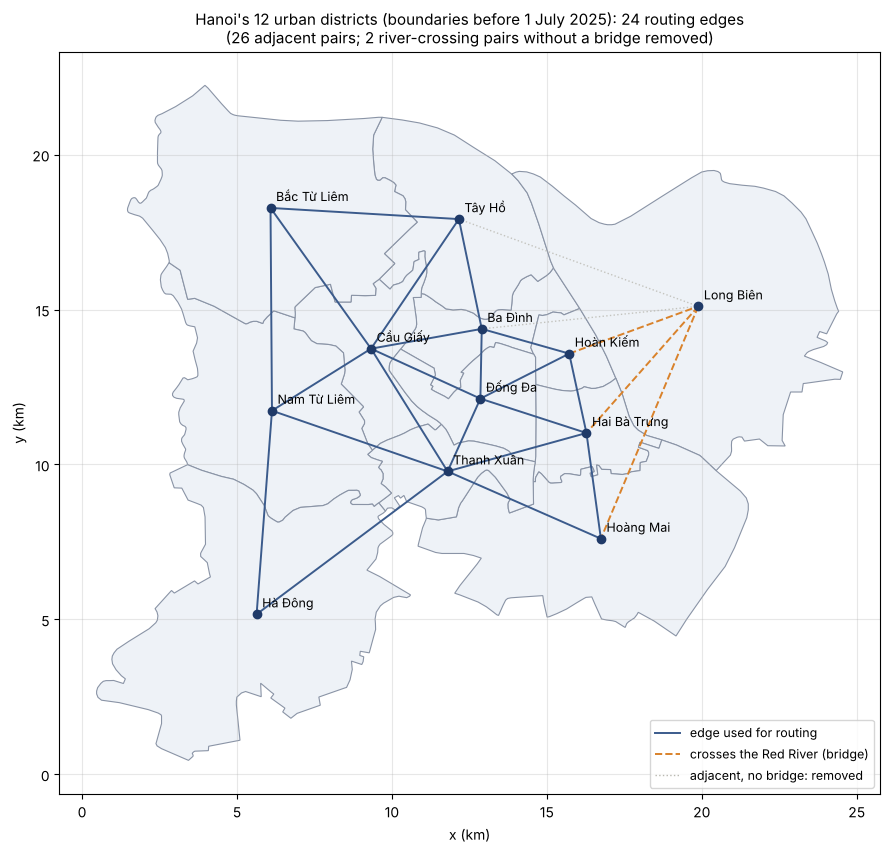

In [9]:
fig, ax = plt.subplots(figsize=(9, 9))
for _, _, hinh in quan:
    for p in getattr(hinh, "geoms", [hinh]):
        x, y = p.exterior.xy
        ax.fill((np.array(x) - goc_x) / 1000, (np.array(y) - goc_y) / 1000,
                fc="#eef2f7", ec="#8a94a6", lw=0.8)

vi_tri = df_tam.set_index("ten")
canh_bo_ve = {tuple(sorted(p)) for p in BO_CANH}
so_giu = 0
for c in canh:
    a, b = vi_tri.loc[c["quan_1"]], vi_tri.loc[c["quan_2"]]
    if tuple(sorted((c["quan_1"], c["quan_2"]))) in canh_bo_ve:
        ax.plot([a.x_km, b.x_km], [a.y_km, b.y_km], color="#b9b8b0", lw=1.0, ls=":", alpha=0.8, zorder=1)
        continue
    so_giu += 1
    qua_song = c["qua_song_hong"] == "có"
    ax.plot([a.x_km, b.x_km], [a.y_km, b.y_km], color="#d9822b" if qua_song else "#3b5b8c",
            lw=1.4, ls="--" if qua_song else "-", zorder=2)
from matplotlib.lines import Line2D
ax.legend([Line2D([], [], color="#3b5b8c", lw=1.4), Line2D([], [], color="#d9822b", lw=1.4, ls="--"),
           Line2D([], [], color="#b9b8b0", lw=1.0, ls=":")],
          ["edge used for routing", "crosses the Red River (bridge)", "adjacent, no bridge: removed"],
          loc="lower right", fontsize=9)

for ten, t in vi_tri.iterrows():
    ax.scatter(t.x_km, t.y_km, s=36, color="#1f3a68", zorder=3)
    ax.annotate(ten, (t.x_km, t.y_km), xytext=(4, 5), textcoords="offset points", fontsize=9, zorder=4)

ax.set_aspect("equal")
ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_title(f"Hanoi's 12 urban districts (boundaries before 1 July 2025): {so_giu} routing edges\n"
             f"({len(canh)} adjacent pairs; {len(canh) - so_giu} river-crossing pairs without a bridge removed)", fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(THU_MUC_KET_QUA, "hanoi_12_quan_ban_do.png"), dpi=130)
plt.show()

## 1.9 Ghi kết quả

- `hanoi_12_quan_toa_do.csv`: tâm quận (mã, tên, kinh độ, vĩ độ, x_km, y_km, diện tích).
- `hanoi_12_quan_ke_nhau.csv`: các cặp quận kề nhau và khoảng cách đường chim bay.
- `hanoi_12_quan_ban_do.png`: bản đồ kiểm tra.
- `metadata.json`: nguồn, mã băm, ngày dữ liệu, tham số và kết quả kiểm tra.

File CSV được ghi với mã hóa `utf-8-sig` để Excel hiển thị đúng tiếng Việt.

In [10]:
df_tam.to_csv(os.path.join(THU_MUC_KET_QUA, "hanoi_12_quan_toa_do.csv"), index=False, encoding="utf-8-sig")
df_canh.to_csv(os.path.join(THU_MUC_KET_QUA, "hanoi_12_quan_ke_nhau.csv"), index=False, encoding="utf-8-sig")

metadata = {
    "nguon_ranh_gioi": nguon,
    "sha256_file_ranh_gioi": ma_bam,
    "ngay_du_lieu_dvhcvn": ngay_du_lieu,
    "thoi_diem_chay_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "he_quy_chieu": f"{HE_QUY_CHIEU} (WGS 84 / UTM zone 48N)",
    "goc_toa_do_utm_m": {"x": goc_x, "y": goc_y},
    "tam_quan": "trọng tâm hình học (centroid) của đa giác ranh giới",
    "dieu_kien_ke_nhau": f"chung ranh giới > {NGUONG_BIEN_CHUNG_M} m (dung sai {DUNG_SAI_RANH_GIOI_M} m)",
    "so_quan": len(df_tam),
    "so_cap_ke_nhau": len(df_canh),
    "sai_lech_lon_nhat_phang_vs_trac_dia_km": round(float(sai_lech), 4),
}
if df_doi_chieu is not None:
    metadata["doi_chieu_geoboundaries_km"] = dict(zip(df_doi_chieu.ten, df_doi_chieu.lech_km))
    metadata["doi_chieu_lech_lon_nhat_km"] = float(df_doi_chieu.lech_km.max())

with open(os.path.join(THU_MUC_KET_QUA, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Đã ghi vào thư mục:", os.path.abspath(THU_MUC_KET_QUA))
for ten_file in sorted(os.listdir(THU_MUC_KET_QUA)):
    print("  -", ten_file)

Đã ghi vào thư mục: /home/claude/hanoi_tim_duong/ket_qua
  - hanoi_12_quan_ban_do.png
  - hanoi_12_quan_ke_nhau.csv
  - hanoi_12_quan_toa_do.csv
  - mau_do_dai_duong_thuc.csv
  - metadata.json
  - thi_nghiem


# Phần 2. Cài đặt thuật toán và kiểm chứng

## 2.1 Dựng đồ thị

Mỗi node là tâm một quận, mỗi cạnh là một cặp quận kề nhau (bảng `df_canh` ở mục 1.6). Chi phí cạnh là độ dài đường thật, lấy theo thứ tự ưu tiên:

1. Biến `DO_DAI_DUONG_THUC` trong ô dưới.
2. File `real_road_data.csv` đặt cạnh notebook, nếu có. Notebook ghi sẵn một file mẫu `ket_qua/mau_do_dai_duong_thuc.csv` gồm đủ 26 cặp quận: nhóm điền cột `do_dai_duong_thuc_km` (tra Google Maps), rồi lưu thành `real_road_data.csv` cạnh notebook. Notebook không bao giờ ghi đè file này.
3. Nếu chưa có số liệu thật: tạm dùng khoảng cách đường chim bay giữa hai tâm quận.

`BO_CANH` (khai báo ở mục 1.1) bỏ những cặp qua sông Hồng không có cầu nối trực tiếp.

In [11]:
import heapq
import platform
import random
import sys
import time
from collections import Counter, deque

# ----- Tham số đồ thị -----
# Độ dài đường thật (km), ví dụ: {("Ba Đình", "Hoàn Kiếm"): 3.6, ("Cầu Giấy", "Đống Đa"): 4.5}
DO_DAI_DUONG_THUC = {}
FILE_DO_DAI = "real_road_data.csv"   # file nhóm tự điền (không bị notebook ghi đè)
# BO_CANH: khai báo ở mục 1.1 (cặp qua sông không có cầu)
EPS = 1e-9
# Cạnh đo được NGẮN hơn đường chim bay giữa hai tâm quận (do đo giữa hai điểm khác tâm quận)
# thì nâng lên bằng đường chim bay để heuristic vẫn nhất quán. Danh sách cạnh bị nâng được in ra.
NANG_CANH_HUT = True


def khoa(a, b):
    # (a, b) và (b, a) là cùng một cạnh
    return tuple(sorted((a, b)))


class DoThi:
    # Đồ thị vô hướng có trọng số: node = tâm quận, cạnh = cặp quận kề nhau.
    def __init__(self, toa_do, ma, chi_phi_canh):
        self.toa_do = toa_do              # tên -> (x_km, y_km)
        self.key = ma                      # tên -> mã hành chính, dùng để phá hòa điểm
        self.chi_phi_canh = chi_phi_canh  # (a, b) -> km
        self.neighbors = {n: [] for n in toa_do}
        for a, b in chi_phi_canh:
            self.neighbors[a].append(b)
            self.neighbors[b].append(a)
        for n in self.neighbors:
            self.neighbors[n].sort(key=lambda m: ma[m])   # hòa điểm: mã nhỏ trước

    def cost(self, a, b):
        return self.chi_phi_canh[khoa(a, b)]

    def h(self, n, goal):
        # Heuristic: khoảng cách Euclidean (đường chim bay) từ n đến đích, đơn vị km
        return math.dist(self.toa_do[n], self.toa_do[goal])


toa_do = {r.ten: (float(r.x_km), float(r.y_km)) for r in df_tam.itertuples()}
ma_quan = {r.ten: str(r.ma) for r in df_tam.itertuples()}
cap_ke_nhau = [khoa(r.quan_1, r.quan_2) for r in df_canh.itertuples()]

# Đọc độ dài đường thật: file trước, rồi dict ghi đè
do_dai_thuc = {}
if os.path.exists(FILE_DO_DAI):
    for r in pd.read_csv(FILE_DO_DAI, encoding="utf-8-sig").itertuples():
        if pd.notna(r.do_dai_duong_thuc_km) and str(r.do_dai_duong_thuc_km).strip():
            do_dai_thuc[khoa(r.quan_1, r.quan_2)] = float(r.do_dai_duong_thuc_km)
do_dai_thuc.update({khoa(a, b): float(v) for (a, b), v in DO_DAI_DUONG_THUC.items()})
canh_bo = {khoa(a, b) for a, b in BO_CANH}
for k in sorted(set(do_dai_thuc) | canh_bo):
    if k not in cap_ke_nhau:
        print(f"Cảnh báo: {k} không phải hai quận kề nhau, bị bỏ qua.")

chi_phi = {}
nguon_do_dai = Counter()
canh_nang = []
for k in cap_ke_nhau:
    if k in canh_bo:
        continue
    if k in do_dai_thuc:
        chim_bay = math.dist(toa_do[k[0]], toa_do[k[1]])
        if NANG_CANH_HUT and do_dai_thuc[k] < chim_bay:
            canh_nang.append({"Cạnh": f"{k[0]} – {k[1]}", "Đo được (km)": do_dai_thuc[k],
                              "Đường chim bay (km)": round(chim_bay, 3), "Dùng (km)": round(chim_bay, 3)})
            chi_phi[k] = chim_bay
            nguon_do_dai["thực, nâng lên chim bay"] += 1
        else:
            chi_phi[k] = do_dai_thuc[k]
            nguon_do_dai["thực"] += 1
    else:
        chi_phi[k] = math.dist(toa_do[k[0]], toa_do[k[1]])
        nguon_do_dai["chim bay"] += 1
    if chi_phi[k] <= 0:
        raise ValueError(f"Độ dài cạnh {k} phải dương")

G = DoThi(toa_do, ma_quan, chi_phi)

# Đồ thị phải liên thông, nếu không sẽ có cặp (kho, đích) không có đường
da_gap, hang_doi = {next(iter(toa_do))}, deque([next(iter(toa_do))])
while hang_doi:
    for m in G.neighbors[hang_doi.popleft()]:
        if m not in da_gap:
            da_gap.add(m)
            hang_doi.append(m)
if len(da_gap) != len(toa_do):
    raise ValueError(f"Đồ thị không liên thông sau khi bỏ cạnh: không đến được {set(toa_do) - da_gap}")

# File mẫu để nhóm điền độ dài đường thật
pd.DataFrame([{
    "quan_1": a, "quan_2": b,
    "qua_song_hong": "có" if "Long Biên" in (a, b) else "không",
    "duong_chim_bay_km": round(math.dist(toa_do[a], toa_do[b]), 3),
    "do_dai_duong_thuc_km": do_dai_thuc.get((a, b), ""),
} for a, b in cap_ke_nhau]).to_csv(os.path.join(THU_MUC_KET_QUA, "mau_do_dai_duong_thuc.csv"),
                                    index=False, encoding="utf-8-sig")

print(f"Đồ thị: {len(G.toa_do)} node, {len(G.chi_phi_canh)} cạnh (đã bỏ {len(canh_bo & set(cap_ke_nhau))} cạnh theo BO_CANH)")
print(f"Độ dài cạnh: {nguon_do_dai['thực']} cạnh dùng độ dài đường thật, "
      f"{nguon_do_dai['thực, nâng lên chim bay']} cạnh đo được ngắn hơn đường chim bay nên được nâng lên, "
      f"{nguon_do_dai['chim bay']} cạnh chưa có số liệu (tạm dùng đường chim bay)")
if canh_nang:
    display(pd.DataFrame(canh_nang))
if nguon_do_dai["chim bay"]:
    print("  -> Chưa đủ độ dài đường thật: kết quả ở Phần 5 hiện chỉ mang tính minh họa.")

Đồ thị: 12 node, 24 cạnh (đã bỏ 2 cạnh theo BO_CANH)
Độ dài cạnh: 20 cạnh dùng độ dài đường thật, 4 cạnh đo được ngắn hơn đường chim bay nên được nâng lên, 0 cạnh chưa có số liệu (tạm dùng đường chim bay)


,Cạnh,Đo được (km),Đường chim bay (km),Dùng (km)
0,Ba Đình – Hoàn Kiếm,1.8,2.933,2.933
1,Hai Bà Trưng – Hoàn Kiếm,2.5,2.622,2.622
2,Hà Đông – Thanh Xuân,4.5,7.698,7.698
3,Hà Đông – Nam Từ Liêm,5.1,6.589,6.589


## 2.2 Ba thuật toán (và UCS làm đối chứng)

Quy ước chung cho mọi thuật toán (khớp mục V của báo cáo):

- Kiểm tra đích khi **lấy node ra khỏi frontier**, không phải lúc sinh node.
- **Graph search**: mỗi node chỉ được mở rộng một lần.
- **Node mở rộng** = node được lấy ra khỏi frontier rồi sinh hàng xóm. Không đếm node đích.
- **Hòa điểm**: ưu tiên quận có mã hành chính nhỏ hơn.

| Thuật toán | Frontier | Dùng độ dài cạnh khi chọn? | Dùng heuristic? |
|---|---|---|---|
| BFS | Hàng đợi FIFO | Không | Không |
| GBFS | Hàng đợi ưu tiên theo h(n) | Không | Có |
| A\* | Hàng đợi ưu tiên theo f(n) = g(n) + h(n) | Có | Có |
| UCS (đối chứng) | Hàng đợi ưu tiên theo g(n), tức A\* với h = 0 | Có | Không |

Mỗi hàm trả về: đường đi, danh sách node mở rộng, số node sinh ra, kích thước frontier lớn nhất, và số km thuật toán tự cộng dồn (BFS và GBFS chỉ ghi lại km để kiểm chứng, không dùng km để ra quyết định).

In [12]:
def build_path(parent, goal):
    # Rebuild the path by following parent links back from the goal
    path = [goal]
    while parent[path[-1]] is not None:
        path.append(parent[path[-1]])
    return path[::-1]


def tong_km(G, path):
    return sum(G.cost(path[i], path[i + 1]) for i in range(len(path) - 1))


def make_result(path, expanded, generated, frontier_max, km):
    return {"duong": path, "mo_rong": expanded, "so_node_sinh": generated,
            "frontier_max": frontier_max, "km_ghi_nhan": km}


def bfs(G, depot, goal):
    frontier = deque([depot])
    parent = {depot: None}  # also serves as the set of seen nodes
    g = {depot: 0.0}        # km travelled, for verification only
    expanded, generated, max_frontier = [], 1, 1
    while frontier:
        n = frontier.popleft()                 # FIFO: oldest node first
        if n == goal:                          # goal test on removal
            return make_result(build_path(parent, goal), expanded, generated, max_frontier, g[goal])
        expanded.append(n)                     # count one expanded node
        for m in G.neighbors[n]:
            if m not in parent:                # graph search: skip seen nodes
                parent[m], g[m] = n, g[n] + G.cost(n, m)
                frontier.append(m)
                generated += 1
        max_frontier = max(max_frontier, len(frontier))
    return make_result(None, expanded, generated, max_frontier, math.nan)


def gbfs(G, depot, goal):
    frontier = [(G.h(depot, goal), G.key[depot], depot)]   # heap ordered by (h, tie-break key)
    parent = {depot: None}
    g = {depot: 0.0}        # km travelled, for verification only
    expanded, generated, max_frontier = [], 1, 1
    while frontier:
        _, _, n = heapq.heappop(frontier)      # node with the smallest h(n)
        if n == goal:                          # goal test on removal
            return make_result(build_path(parent, goal), expanded, generated, max_frontier, g[goal])
        expanded.append(n)
        for m in G.neighbors[n]:
            if m not in parent:                # graph search: skip seen nodes
                parent[m], g[m] = n, g[n] + G.cost(n, m)
                heapq.heappush(frontier, (G.h(m, goal), G.key[m], m))
                generated += 1
        max_frontier = max(max_frontier, len(frontier))
    return make_result(None, expanded, generated, max_frontier, math.nan)


def a_star(G, depot, goal, use_heuristic=True):
    h = (lambda n: G.h(n, goal)) if use_heuristic else (lambda n: 0.0)
    g = {depot: 0.0}                           # best known cost to each node
    parent = {depot: None}
    frontier = [(h(depot), G.key[depot], depot)]   # heap ordered by (f, tie-break key)
    closed = set()                             # expanded nodes
    expanded, generated, max_frontier = [], 1, 1
    while frontier:
        _, _, n = heapq.heappop(frontier)      # node with the smallest f = g + h
        if n in closed:
            continue                           # stale entry: a better path was found later
        if n == goal:                          # goal test on removal
            return make_result(build_path(parent, goal), expanded, generated, max_frontier, g[goal])
        closed.add(n)
        expanded.append(n)
        for m in G.neighbors[n]:
            if m in closed:
                continue                       # never reopen an expanded node
            new_g = g[n] + G.cost(n, m)
            if m not in g or new_g < g[m] - EPS:
                g[m], parent[m] = new_g, n     # better path: update g and parent
                heapq.heappush(frontier, (new_g + h(m), G.key[m], m))
                generated += 1
        max_frontier = max(max_frontier, len(frontier))
    return make_result(None, expanded, generated, max_frontier, math.nan)


def ucs(G, depot, goal):
    # UCS (Dijkstra) is A* with h = 0
    return a_star(G, depot, goal, use_heuristic=False)


THUAT_TOAN = {"BFS": bfs, "GBFS": gbfs, "A*": a_star, "UCS": ucs}

## 2.3 Kiểm chứng

Mỗi lần chạy một thuật toán cho một cặp (kho, đích) đều được kiểm chứng:

1. **Đường hợp lệ**: bắt đầu ở kho, kết thúc ở đích, mỗi bước là một cạnh có thật, không lặp quận.
2. **Tổng km khớp**: km tính lại từ từng cạnh của đường đi bằng km thuật toán tự cộng dồn.
3. **Tiêu chí riêng**, so với đáp án **vét cạn** (liệt kê mọi đường đi đơn từ kho đến đích):
   - BFS: số cạnh phải ít nhất có thể.
   - A\* và UCS: tổng km phải ngắn nhất có thể.
   - GBFS: không đảm bảo tối ưu, nên so với một cài đặt GBFS thứ hai viết độc lập (quét danh sách, không dùng heap): phải ra cùng thứ tự mở rộng và cùng đường đi.

Ngoài ra, heuristic Euclidean được kiểm tra **nhất quán** trên mọi cạnh và mọi đích: h(n) ≤ c(n, m) + h(m). Đây là điều kiện để A\* (graph search) chắc chắn tìm được đường ngắn nhất.

In [13]:
def vet_can(G, depot, goal):
    # Liệt kê mọi đường đi đơn từ kho đến đích: đáp án chuẩn để kiểm chứng
    kq = {"so_duong": 0, "it_canh": math.inf, "ngan_nhat_km": math.inf, "duong_ngan_nhat": None}

    def dfs(n, path, da_qua, km):
        if n == goal:
            kq["so_duong"] += 1
            kq["it_canh"] = min(kq["it_canh"], len(path) - 1)
            if km < kq["ngan_nhat_km"] - EPS:
                kq["ngan_nhat_km"], kq["duong_ngan_nhat"] = km, list(path)
            return
        for m in G.neighbors[n]:
            if m not in da_qua:
                path.append(m)
                da_qua.add(m)
                dfs(m, path, da_qua, km + G.cost(n, m))
                da_qua.discard(m)
                path.pop()

    dfs(depot, [depot], {depot}, 0.0)
    return kq


def gbfs_doc_lap(G, depot, goal):
    # GBFS cài theo cách khác: mỗi bước quét cả danh sách frontier để chọn h nhỏ nhất
    frontier, parent, expanded = [depot], {depot: None}, []
    while frontier:
        n = min(frontier, key=lambda x: (G.h(x, goal), G.key[x]))
        frontier.remove(n)
        if n == goal:
            return build_path(parent, goal), expanded
        expanded.append(n)
        for m in G.neighbors[n]:
            if m not in parent:
                parent[m] = n
                frontier.append(m)
    return None, expanded


def duong_hop_le(G, path, depot, goal):
    return (path is not None and path[0] == depot and path[-1] == goal
            and len(set(path)) == len(path)
            and all(khoa(path[i], path[i + 1]) in G.chi_phi_canh for i in range(len(path) - 1)))


def kiem_tra_heuristic(G):
    # Trả về danh sách vi phạm h(a) > c(a, b) + h(b), xét mọi cạnh theo hai chiều và mọi đích
    return [(a, b, d) for d in G.toa_do for (x, y) in G.chi_phi_canh for a, b in ((x, y), (y, x))
            if G.h(a, d) > G.cost(a, b) + G.h(b, d) + EPS]


def kiem_chung(G, depot, goal, ten_tt, kq, dap_an):
    path = kq["duong"]
    hop_le = duong_hop_le(G, path, depot, goal)
    km = tong_km(G, path) if hop_le else math.nan
    km_khop = hop_le and abs(km - kq["km_ghi_nhan"]) < EPS
    if ten_tt == "BFS":
        tieu_chi = hop_le and len(path) - 1 == dap_an["it_canh"]
        chi_tiet = f"số cạnh {len(path) - 1 if path else '?'} / ít nhất {dap_an['it_canh']}"
    elif ten_tt in ("A*", "UCS"):
        tieu_chi = hop_le and abs(km - dap_an["ngan_nhat_km"]) < EPS
        chi_tiet = f"{km:.3f} km / ngắn nhất {dap_an['ngan_nhat_km']:.3f} km"
    else:
        duong_2, mo_rong_2 = gbfs_doc_lap(G, depot, goal)
        tieu_chi = path == duong_2 and kq["mo_rong"] == mo_rong_2
        chi_tiet = "khớp cài đặt độc lập" if tieu_chi else "KHÔNG khớp cài đặt độc lập"
    return {"hop_le": hop_le, "km": km, "dat": bool(hop_le and km_khop and tieu_chi), "chi_tiet": chi_tiet}


vi_pham = kiem_tra_heuristic(G)
if vi_pham:
    print(f"Heuristic KHÔNG nhất quán ở {len(vi_pham)} chỗ (có cạnh ngắn hơn đường chim bay?):")
    for a, b, d in vi_pham[:10]:
        print(f"   đích {d}: h({a}) = {G.h(a, d):.3f} > c({a}, {b}) + h({b}) = {G.cost(a, b) + G.h(b, d):.3f}")
    raise AssertionError("Heuristic không nhất quán: kiểm tra lại độ dài đường đã điền.")
print("Heuristic Euclidean nhất quán trên mọi cạnh và mọi đích -> A* chắc chắn tìm được đường ngắn nhất.")

Heuristic Euclidean nhất quán trên mọi cạnh và mọi đích -> A* chắc chắn tìm được đường ngắn nhất.


## 2.4 Hàm chạy một kịch bản thí nghiệm

`chay_thi_nghiem` chạy cả 4 thuật toán cho một danh sách cặp (kho, đích), ghi lại các chỉ số đo và kết quả kiểm chứng của từng lần chạy vào một bảng.

In [14]:
def chay_thi_nghiem(G, cac_cap, lap_do_thoi_gian=0, nhan=None):
    hang = []
    for depot, goal in cac_cap:
        dap_an = vet_can(G, depot, goal)
        for ten_tt, ham in THUAT_TOAN.items():
            kq = ham(G, depot, goal)
            kc = kiem_chung(G, depot, goal, ten_tt, kq, dap_an)
            path = kq["duong"]
            dong = {
                "Kho": depot,
                "Đích": goal,
                "Thuật toán": ten_tt,
                "Đường đi": " → ".join(path) if path else "không tìm thấy",
                "Số cạnh": len(path) - 1 if path else None,
                "Tổng km": kc["km"],
                "Ngắn nhất (km)": dap_an["ngan_nhat_km"],
                "Ít cạnh nhất": dap_an["it_canh"],
                "Tối ưu": bool(kc["hop_le"] and abs(kc["km"] - dap_an["ngan_nhat_km"]) < EPS),
                "Vượt tối ưu (%)": 100 * (kc["km"] / dap_an["ngan_nhat_km"] - 1),
                "Node mở rộng": len(kq["mo_rong"]),
                "Node sinh ra": kq["so_node_sinh"],
                "Frontier lớn nhất": kq["frontier_max"],
                "Thứ tự mở rộng": ", ".join(kq["mo_rong"]),
                "Kiểm chứng": "ĐẠT" if kc["dat"] else "LỖI",
                "Chi tiết kiểm chứng": kc["chi_tiet"],
            }
            if lap_do_thoi_gian:
                t0 = time.perf_counter_ns()
                for _ in range(lap_do_thoi_gian):
                    ham(G, depot, goal)
                dong["Thời gian (µs)"] = (time.perf_counter_ns() - t0) / lap_do_thoi_gian / 1000
            if nhan:
                dong.update(nhan)
            hang.append(dong)
    return pd.DataFrame(hang)


def tom_tat_kiem_chung(df, ten):
    loi = df[df["Kiểm chứng"] == "LỖI"]
    print(f"Kiểm chứng {ten}: {len(df) - len(loi)}/{len(df)} lần chạy đạt.")
    if len(loi):
        display(loi[["Kho", "Đích", "Thuật toán", "Chi tiết kiểm chứng"]])
        raise AssertionError(f"{ten}: có {len(loi)} lần chạy không qua kiểm chứng.")

# 5. Experiments & Results

## 5.1 Setup

**Môi trường:** in ra ở ô dưới (phiên bản Python, hệ điều hành, thư viện).

**Dữ liệu:** đồ thị 12 node (tâm 12 quận Hà Nội, ranh giới trước 01/07/2025) và các cạnh là cặp quận kề nhau (Phần 1, Phần 2.1). Chi phí cạnh là độ dài đường thật nếu nhóm đã điền, nếu chưa thì tạm là đường chim bay. Heuristic h(n) là khoảng cách Euclidean từ tâm quận n đến tâm quận đích.

**Các chỉ số đo** cho mỗi lần chạy (một thuật toán, một cặp kho–đích):

| Chỉ số | Ý nghĩa |
|---|---|
| Node mở rộng | Số node được lấy ra khỏi frontier và sinh hàng xóm (không tính node đích) |
| Node sinh ra | Số lần một node được đưa vào frontier (tính cả kho) |
| Frontier lớn nhất | Số phần tử lớn nhất trong frontier, đại diện cho bộ nhớ (A\*/UCS tính cả bản ghi cũ) |
| Tổng km, Số cạnh | Độ dài và số chặng của đường đi tìm được |
| Tối ưu | Tổng km có bằng đường ngắn nhất (theo vét cạn) không |
| Vượt tối ưu (%) | Tổng km dài hơn đường ngắn nhất bao nhiêu phần trăm |
| Thời gian (µs) | Thời gian chạy trung bình qua nhiều lần lặp; trên đồ thị 12 node con số này rất nhỏ và chịu nhiều nhiễu, chỉ để tham khảo |

**Các kịch bản thí nghiệm:**

- **KB1, minh họa chi tiết:** kho đặt ở Ba Đình, 4 khách hàng không kề trực tiếp với kho (cách 2–3 cạnh), nằm ở các hướng khác nhau: Hoàng Mai, Hà Đông, Bắc Từ Liêm, Nam Từ Liêm. Dùng để xem từng đường đi cụ thể.
- **KB2, mọi vị trí kho:** kho lần lượt đặt ở cả 12 quận; với mỗi kho, đích là 11 quận còn lại. Cách này không phải chọn tay vị trí kho hay khách hàng, và cho biết kết luận có phụ thuộc vào vị trí kho hay không.
- **KB3, độ nhạy theo độ quanh co của đường (mô phỏng):** đường thật luôn dài hơn đường chim bay. KB3 mô phỏng điều đó bằng cách nhân độ dài đường chim bay của mỗi cạnh với một hệ số ngẫu nhiên trong khoảng [1, k], với k = 1,0; 1,25; 1,5; 2,0, lặp nhiều lần với seed cố định. Mục đích: xem heuristic Euclidean còn hữu ích đến đâu khi đường càng quanh co. Số liệu KB3 là **mô phỏng**, không phải số liệu đường thật.

Mọi lần chạy ở cả ba kịch bản đều qua bước kiểm chứng ở mục 2.3. Có lần nào không đạt thì notebook dừng lại và báo lỗi.

In [15]:
# ----- Tham số thí nghiệm -----
KB1_KHO = "Ba Đình"
KB1_KHACH_HANG = ["Hoàng Mai", "Hà Đông", "Bắc Từ Liêm", "Nam Từ Liêm"]
KB3_HE_SO_TOI_DA = [1.0, 1.25, 1.5, 2.0]   # mỗi cạnh = đường chim bay × U(1, k)
KB3_SO_LAN_LAP = 20                        # số bản đồ ngẫu nhiên cho mỗi k > 1
KB3_SEED = 2026
LAP_DO_THOI_GIAN = 30                      # số lần lặp khi đo thời gian (KB1, KB2)
THU_MUC_THI_NGHIEM = os.path.join(THU_MUC_KET_QUA, "thi_nghiem")
os.makedirs(THU_MUC_THI_NGHIEM, exist_ok=True)

for ten in [KB1_KHO, *KB1_KHACH_HANG]:
    if ten not in G.toa_do:
        raise ValueError(f"Không có quận '{ten}'")

# Màu cố định cho từng thuật toán (dùng ở mọi biểu đồ)
MAU = {"BFS": "#2a78d6", "GBFS": "#eb6834", "A*": "#1baf7a", "UCS": "#eda100"}
THU_TU_TT = list(THUAT_TOAN)
plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "normal",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "text.color": "#0b0b0b", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e7e6e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "legend.frameon": False, "figure.dpi": 110,
})

# ----- Môi trường -----
import matplotlib, pyproj
moi_truong = pd.DataFrame([
    ("Python", platform.python_version()),
    ("Hệ điều hành", platform.platform()),
    ("Số nhân CPU", os.cpu_count()),
    ("numpy", np.__version__), ("pandas", pd.__version__), ("shapely", shapely.__version__),
    ("pyproj", pyproj.__version__), ("matplotlib", matplotlib.__version__),
], columns=["Thành phần", "Phiên bản / giá trị"])
display(moi_truong)

# ----- Dữ liệu -----
print(f"Đồ thị: {len(G.toa_do)} node, {len(G.chi_phi_canh)} cạnh; "
      f"{nguon_do_dai['thực']} cạnh có độ dài thật, {nguon_do_dai['chim bay']} cạnh tạm dùng đường chim bay.")

# ----- Số lần chạy -----
so_cap_kb2 = len(G.toa_do) * (len(G.toa_do) - 1)
so_ban_do_kb3 = sum(1 if k == 1.0 else KB3_SO_LAN_LAP for k in KB3_HE_SO_TOI_DA)
kich_ban = pd.DataFrame([
    ("KB1", f"Kho {KB1_KHO}, {len(KB1_KHACH_HANG)} khách hàng", 1, len(KB1_KHACH_HANG), len(KB1_KHACH_HANG) * 4),
    ("KB2", "Kho ở mỗi quận, đích là 11 quận còn lại", 1, so_cap_kb2, so_cap_kb2 * 4),
    ("KB3", f"Đường quanh co mô phỏng, k ∈ {KB3_HE_SO_TOI_DA}", so_ban_do_kb3, so_cap_kb2, so_ban_do_kb3 * so_cap_kb2 * 4),
], columns=["Kịch bản", "Mô tả", "Số bản đồ", "Số cặp (kho, đích) mỗi bản đồ", "Số lần chạy thuật toán"])
display(kich_ban)
print(f"Thời gian được đo ở KB1 và KB2, mỗi lần chạy lặp {LAP_DO_THOI_GIAN} lần rồi lấy trung bình.")

,Thành phần,Phiên bản / giá trị
0,Python,3.13.16
1,Hệ điều hành,Linux-6.18.44-fc-v139-x86_64-with-glibc2.39
2,Số nhân CPU,2
3,numpy,2.5.3
4,pandas,3.0.5
5,shapely,2.2.0
6,pyproj,3.8.0
7,matplotlib,3.11.2


Đồ thị: 12 node, 24 cạnh; 20 cạnh có độ dài thật, 0 cạnh tạm dùng đường chim bay.


,Kịch bản,Mô tả,Số bản đồ,"Số cặp (kho, đích) mỗi bản đồ",Số lần chạy thuật toán
0,KB1,"Kho Ba Đình, 4 khách hàng",1,4,16
1,KB2,"Kho ở mỗi quận, đích là 11 quận còn lại",1,132,528
2,KB3,"Đường quanh co mô phỏng, k ∈ [1.0, 1.25, 1.5, ...",61,132,32208


Thời gian được đo ở KB1 và KB2, mỗi lần chạy lặp 30 lần rồi lấy trung bình.


## 5.2 Results

### 5.2.1 KB1: kho ở Ba Đình, 4 khách hàng

In [16]:
df_kb1 = chay_thi_nghiem(G, [(KB1_KHO, d) for d in KB1_KHACH_HANG], LAP_DO_THOI_GIAN)
tom_tat_kiem_chung(df_kb1, "KB1")
df_kb1.to_csv(os.path.join(THU_MUC_THI_NGHIEM, "kb1_ket_qua.csv"), index=False, encoding="utf-8-sig")

bang_kb1 = df_kb1[["Đích", "Thuật toán", "Đường đi", "Số cạnh", "Tổng km", "Vượt tối ưu (%)",
                   "Node mở rộng", "Node sinh ra", "Frontier lớn nhất", "Thứ tự mở rộng"]].round(2)
display(bang_kb1)

Kiểm chứng KB1: 16/16 lần chạy đạt.


,Đích,Thuật toán,Đường đi,Số cạnh,Tổng km,Vượt tối ưu (%),Node mở rộng,Node sinh ra,Frontier lớn nhất,Thứ tự mở rộng
0,Hoàng Mai,BFS,Ba Đình → Hoàn Kiếm → Long Biên → Hoàng Mai,3,19.73,75.33,10,12,6,"Ba Đình, Hoàn Kiếm, Tây Hồ, Cầu Giấy, Đống Đa,..."
1,Hoàng Mai,GBFS,Ba Đình → Đống Đa → Hai Bà Trưng → Hoàng Mai,3,14.10,25.28,3,9,6,"Ba Đình, Đống Đa, Hai Bà Trưng"
2,Hoàng Mai,A*,Ba Đình → Hoàn Kiếm → Hai Bà Trưng → Hoàng Mai,3,11.25,0.00,4,10,6,"Ba Đình, Hoàn Kiếm, Hai Bà Trưng, Đống Đa"
3,Hoàng Mai,UCS,Ba Đình → Hoàn Kiếm → Hai Bà Trưng → Hoàng Mai,3,11.25,0.00,8,12,5,"Ba Đình, Hoàn Kiếm, Đống Đa, Tây Hồ, Hai Bà Tr..."
4,Hà Đông,BFS,Ba Đình → Cầu Giấy → Thanh Xuân → Hà Đông,3,19.10,24.03,11,12,6,"Ba Đình, Hoàn Kiếm, Tây Hồ, Cầu Giấy, Đống Đa,..."
5,Hà Đông,GBFS,Ba Đình → Cầu Giấy → Nam Từ Liêm → Hà Đông,3,21.49,39.56,3,9,6,"Ba Đình, Cầu Giấy, Nam Từ Liêm"
6,Hà Đông,A*,Ba Đình → Đống Đa → Thanh Xuân → Hà Đông,3,15.40,0.00,4,11,7,"Ba Đình, Đống Đa, Cầu Giấy, Thanh Xuân"
7,Hà Đông,UCS,Ba Đình → Đống Đa → Thanh Xuân → Hà Đông,3,15.40,0.00,11,12,5,"Ba Đình, Hoàn Kiếm, Đống Đa, Tây Hồ, Hai Bà Tr..."
8,Bắc Từ Liêm,BFS,Ba Đình → Tây Hồ → Bắc Từ Liêm,2,13.30,0.00,7,11,6,"Ba Đình, Hoàn Kiếm, Tây Hồ, Cầu Giấy, Đống Đa,..."
9,Bắc Từ Liêm,GBFS,Ba Đình → Cầu Giấy → Bắc Từ Liêm,2,13.40,0.75,2,8,6,"Ba Đình, Cầu Giấy"


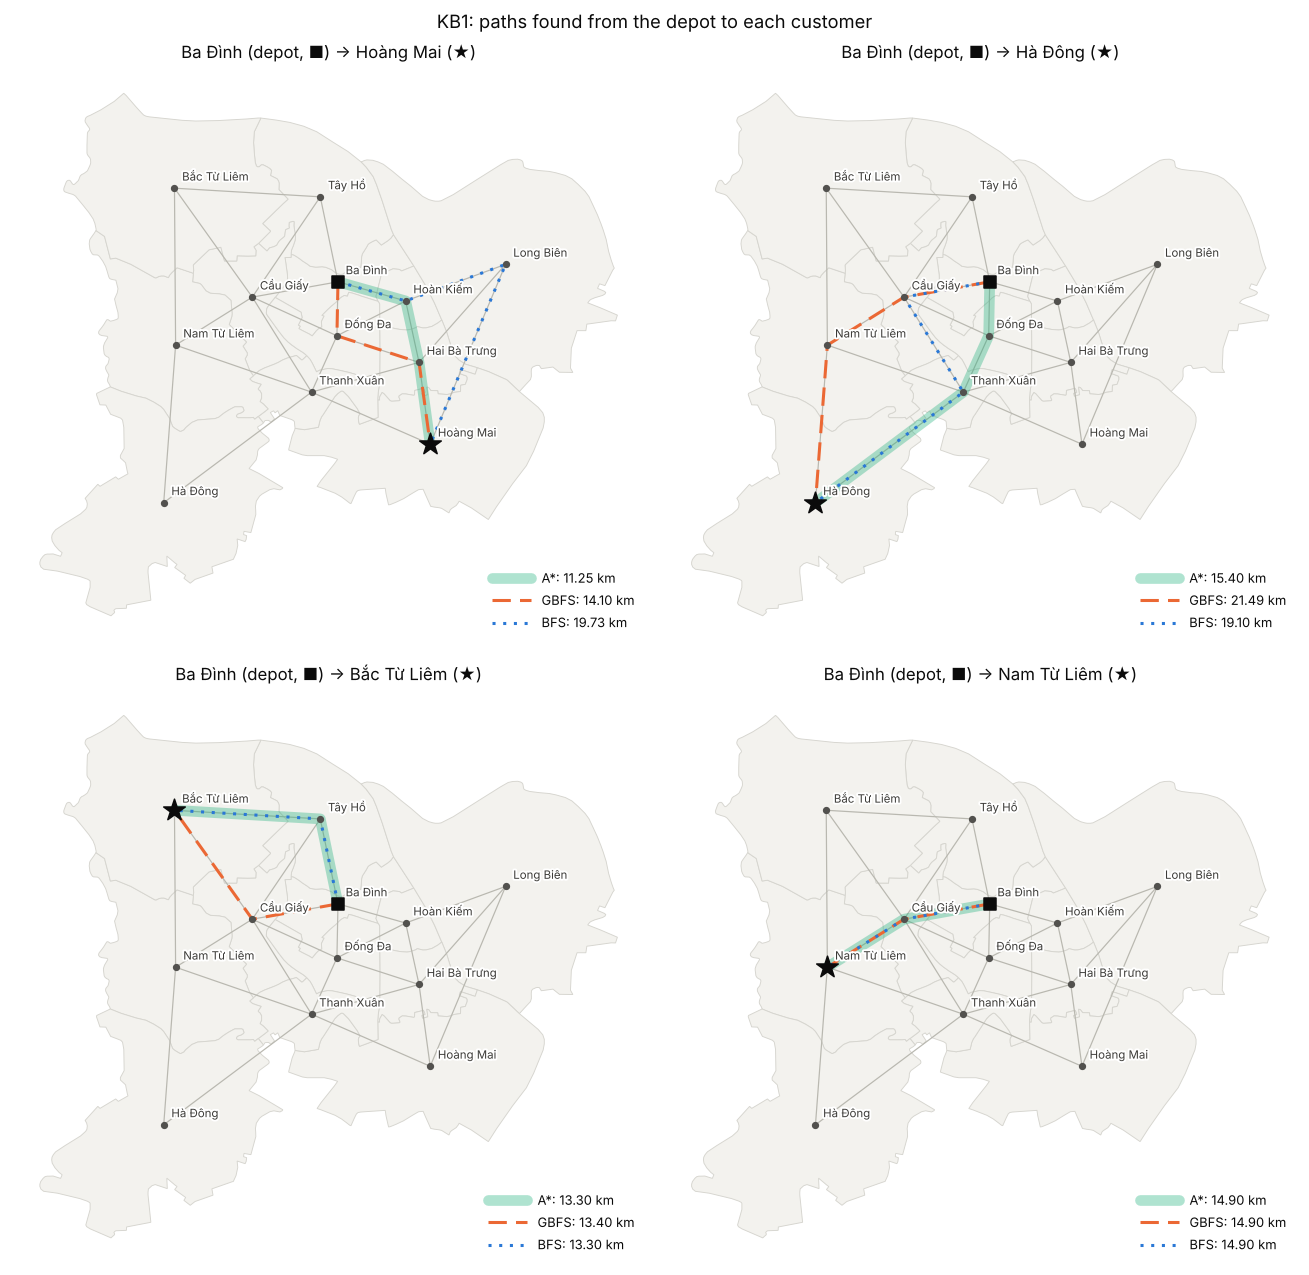

In [17]:
# Figure: paths found by BFS, GBFS and A* on the map, one panel per customer
from matplotlib import patheffects
kieu_duong = {"A*": dict(lw=7, alpha=0.35, solid_capstyle="round", zorder=3),
              "GBFS": dict(lw=2, ls=(0, (6, 3)), zorder=4),
              "BFS": dict(lw=2, ls=(0, (1, 2.5)), zorder=5)}
so_khung = len(KB1_KHACH_HANG)
cot = 2 if so_khung > 1 else 1
dong_khung = math.ceil(so_khung / cot)
fig, axes = plt.subplots(dong_khung, cot, figsize=(6 * cot, 6 * dong_khung), squeeze=False)
for ax, goal in zip(axes.flat, KB1_KHACH_HANG):
    for _, _, hinh in quan:
        for p in getattr(hinh, "geoms", [hinh]):
            x, y = p.exterior.xy
            ax.fill((np.array(x) - goc_x) / 1000, (np.array(y) - goc_y) / 1000, fc="#f3f2ee", ec="#d6d5cf", lw=0.6)
    for a, b in G.chi_phi_canh:
        ax.plot(*zip(G.toa_do[a], G.toa_do[b]), color="#b9b8b0", lw=0.8, zorder=1)
    for ten_tt in ["A*", "GBFS", "BFS"]:
        path = df_kb1[(df_kb1["Đích"] == goal) & (df_kb1["Thuật toán"] == ten_tt)]["Đường đi"].iloc[0].split(" → ")
        km = df_kb1[(df_kb1["Đích"] == goal) & (df_kb1["Thuật toán"] == ten_tt)]["Tổng km"].iloc[0]
        ax.plot(*zip(*[G.toa_do[n] for n in path]), color=MAU[ten_tt], label=f"{ten_tt}: {km:.2f} km", **kieu_duong[ten_tt])
    for ten, (x, y) in G.toa_do.items():
        ax.scatter(x, y, s=14, color="#52514e", zorder=6)
        ax.annotate(ten, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=7.5, color="#3b3a37", zorder=9,
                    path_effects=[patheffects.withStroke(linewidth=2.5, foreground="white")])
    ax.scatter(*G.toa_do[KB1_KHO], marker="s", s=60, color="#0b0b0b", zorder=8)
    ax.scatter(*G.toa_do[goal], marker="*", s=220, color="#0b0b0b", zorder=8)
    ax.set_title(f"{KB1_KHO} (depot, ■) → {goal} (★)")
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.legend(loc="lower right", fontsize=8.5, handlelength=3)
for ax in list(axes.flat)[so_khung:]:
    ax.axis("off")
fig.suptitle("KB1: paths found from the depot to each customer", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(THU_MUC_THI_NGHIEM, "hinh1_kb1_duong_di.png"), dpi=150, bbox_inches="tight")
plt.show()

### 5.2.2 KB2: kho ở mọi quận

Mỗi vị trí kho chạy với 11 đích còn lại. Bảng thứ nhất tổng hợp theo thuật toán, bảng thứ hai cho số node mở rộng trung bình theo từng vị trí kho.

In [18]:
cac_cap_kb2 = [(a, b) for a in G.toa_do for b in G.toa_do if a != b]
df_kb2 = chay_thi_nghiem(G, cac_cap_kb2, LAP_DO_THOI_GIAN)
tom_tat_kiem_chung(df_kb2, "KB2")
df_kb2.to_csv(os.path.join(THU_MUC_THI_NGHIEM, "kb2_ket_qua.csv"), index=False, encoding="utf-8-sig")


def tong_hop_theo_thuat_toan(df):
    return (df.groupby("Thuật toán", sort=False)
            .agg(**{"Số lần chạy": ("Tối ưu", "size"),
                    "Tỷ lệ tối ưu (%)": ("Tối ưu", lambda s: 100 * s.mean()),
                    "Vượt tối ưu TB (%)": ("Vượt tối ưu (%)", "mean"),
                    "Vượt tối ưu lớn nhất (%)": ("Vượt tối ưu (%)", "max"),
                    "Node mở rộng TB": ("Node mở rộng", "mean"),
                    "Node sinh ra TB": ("Node sinh ra", "mean"),
                    "Frontier lớn nhất TB": ("Frontier lớn nhất", "mean"),
                    "Số cạnh TB": ("Số cạnh", "mean")})
            .reindex(THU_TU_TT))


tong_hop_kb2 = tong_hop_theo_thuat_toan(df_kb2)
tong_hop_kb2["Thời gian TB (µs)"] = df_kb2.groupby("Thuật toán")["Thời gian (µs)"].mean().reindex(THU_TU_TT)
display(tong_hop_kb2.round(2))

node_theo_kho = (df_kb2.pivot_table(index="Kho", columns="Thuật toán", values="Node mở rộng", aggfunc="mean")
                 [THU_TU_TT].reindex(list(G.toa_do)))
toi_uu_theo_kho = (df_kb2.pivot_table(index="Kho", columns="Thuật toán", values="Tối ưu", aggfunc="mean")
                   [THU_TU_TT].reindex(list(G.toa_do)) * 100)
print("Node mở rộng trung bình theo vị trí kho:")
display(node_theo_kho.round(2))
print("Tỷ lệ tìm đúng đường ngắn nhất (%) theo vị trí kho:")
display(toi_uu_theo_kho.round(1))

Kiểm chứng KB2: 528/528 lần chạy đạt.


,Số lần chạy,Tỷ lệ tối ưu (%),Vượt tối ưu TB (%),Vượt tối ưu lớn nhất (%),Node mở rộng TB,Node sinh ra TB,Frontier lớn nhất TB,Số cạnh TB,Thời gian TB (µs)
Thuật toán,,,,,,,,,
BFS,132,84.85,5.37,101.88,6.00,9.89,5.34,1.88,6.54
GBFS,132,81.82,3.13,55.49,1.90,7.17,5.27,1.90,5.80
A*,132,100.00,-0.00,0.00,2.87,8.30,5.48,1.94,9.16
UCS,132,100.00,-0.00,0.00,6.00,10.64,5.96,1.94,12.70


Node mở rộng trung bình theo vị trí kho:


Thuật toán,BFS,GBFS,A*,UCS
Kho,,,,
Ba Đình,6.0,1.82,2.55,6.0
Hoàn Kiếm,6.0,1.91,3.00,6.0
Tây Hồ,6.0,2.18,3.00,6.0
Long Biên,6.0,2.36,3.91,6.0
Cầu Giấy,6.0,1.55,2.36,6.0
Đống Đa,6.0,1.55,2.09,6.0
Hai Bà Trưng,6.0,1.73,2.82,6.0
Hoàng Mai,6.0,2.09,3.09,6.0
Thanh Xuân,6.0,1.45,1.91,6.0


Tỷ lệ tìm đúng đường ngắn nhất (%) theo vị trí kho:


Thuật toán,BFS,GBFS,A*,UCS
Kho,,,,
Ba Đình,72.7,72.7,100.0,100.0
Hoàn Kiếm,81.8,81.8,100.0,100.0
Tây Hồ,72.7,72.7,100.0,100.0
Long Biên,100.0,72.7,100.0,100.0
Cầu Giấy,100.0,90.9,100.0,100.0
Đống Đa,90.9,90.9,100.0,100.0
Hai Bà Trưng,100.0,90.9,100.0,100.0
Hoàng Mai,72.7,81.8,100.0,100.0
Thanh Xuân,81.8,81.8,100.0,100.0


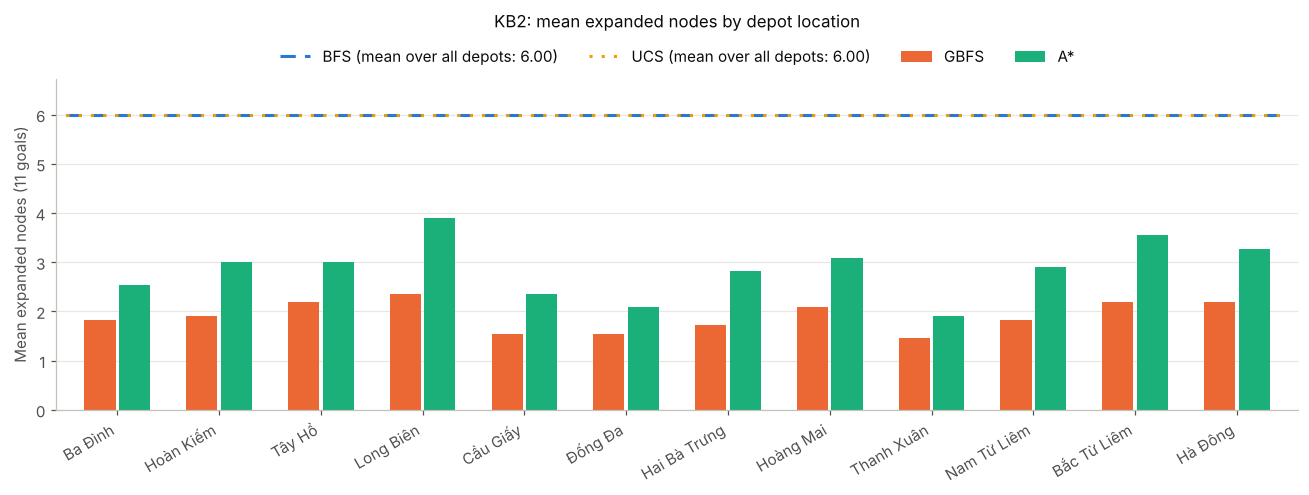

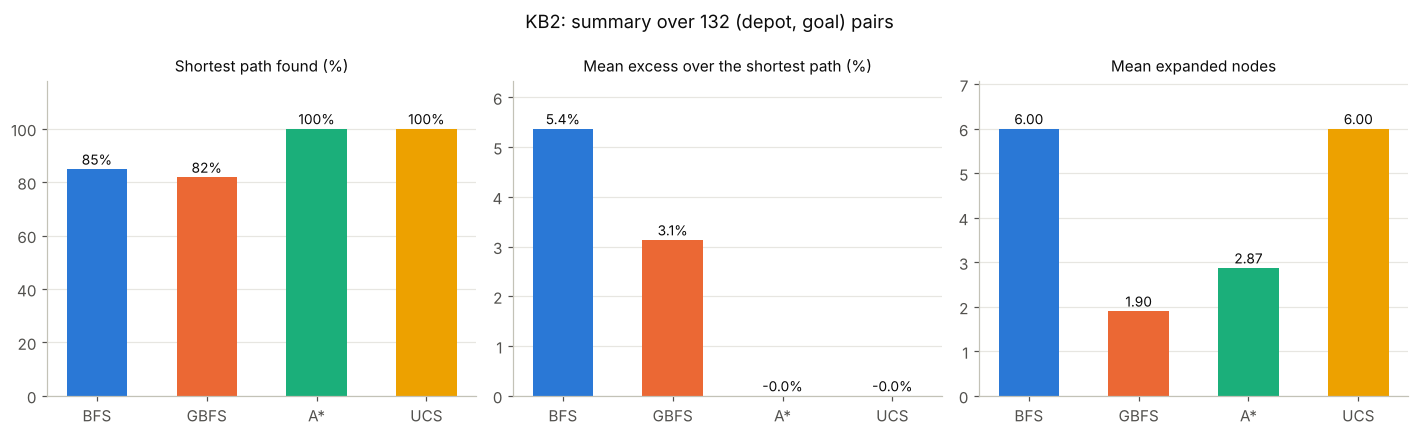

In [19]:
# Figure: mean expanded nodes by depot location.
# BFS and UCS give the same value at every depot, so they are drawn as reference lines.
fig, ax = plt.subplots(figsize=(12, 4.6))
x = np.arange(len(node_theo_kho))
w = 0.34
for i, ten_tt in enumerate(["GBFS", "A*"]):
    ax.bar(x + (i - 0.5) * w, node_theo_kho[ten_tt], width=w * 0.9, color=MAU[ten_tt], label=ten_tt)
for ten_tt, kieu in [("BFS", (0, (5, 3))), ("UCS", (0, (1, 3)))]:
    ax.plot([x[0] - 0.5, x[-1] + 0.5], [node_theo_kho[ten_tt].mean()] * 2, color=MAU[ten_tt], lw=2, ls=kieu,
            label=f"{ten_tt} (mean over all depots: {node_theo_kho[ten_tt].mean():.2f})")
ax.set_xticks(x, node_theo_kho.index, rotation=30, ha="right")
ax.set_xlim(x[0] - 0.6, x[-1] + 0.6)
ax.set_ylim(0, max(node_theo_kho.max()) * 1.12)
ax.set_ylabel("Mean expanded nodes (11 goals)")
ax.grid(axis="x", visible=False)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("KB2: mean expanded nodes by depot location", pad=34)
plt.tight_layout()
plt.savefig(os.path.join(THU_MUC_THI_NGHIEM, "hinh2_kb2_node_theo_kho.png"), dpi=150, bbox_inches="tight")
plt.show()

# Figure: path quality and search cost over all (depot, goal) pairs
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
chi_so = [("Tỷ lệ tối ưu (%)", "Shortest path found (%)", "{:.0f}%"),
          ("Vượt tối ưu TB (%)", "Mean excess over the shortest path (%)", "{:.1f}%"),
          ("Node mở rộng TB", "Mean expanded nodes", "{:.2f}")]
for ax, (cot_df, tieu_de, dinh_dang) in zip(axes, chi_so):
    gia_tri = tong_hop_kb2[cot_df]
    cot_bar = ax.bar(THU_TU_TT, gia_tri, width=0.55, color=[MAU[t] for t in THU_TU_TT])
    for r, v in zip(cot_bar, gia_tri):
        ax.annotate(dinh_dang.format(v), (r.get_x() + r.get_width() / 2, r.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color="#0b0b0b")
    ax.set_title(tieu_de, fontsize=10)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, max(gia_tri.max() * 1.18, 1))
fig.suptitle(f"KB2: summary over {len(cac_cap_kb2)} (depot, goal) pairs", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(THU_MUC_THI_NGHIEM, "hinh3_kb2_tong_hop.png"), dpi=150, bbox_inches="tight")
plt.show()

### 5.2.3 KB3: độ nhạy theo độ quanh co của đường (mô phỏng)

Với mỗi hệ số k, mỗi cạnh có độ dài = đường chim bay × một số ngẫu nhiên trong [1, k]. k = 1,0 nghĩa là mọi đường đều thẳng, nên chỉ cần một bản đồ. Với k > 1, notebook tạo nhiều bản đồ ngẫu nhiên (seed cố định) và chạy đủ các cặp (kho, đích) trên mỗi bản đồ.

In [20]:
duong_chim_bay = {k: math.dist(G.toa_do[k[0]], G.toa_do[k[1]]) for k in G.chi_phi_canh}
ket_qua_kb3 = []
t_bat_dau = time.perf_counter()
for he_so in KB3_HE_SO_TOI_DA:
    so_lan = 1 if he_so == 1.0 else KB3_SO_LAN_LAP
    for lan in range(so_lan):
        rng = random.Random(f"{KB3_SEED}-{he_so}-{lan}")
        G_mo_phong = DoThi(G.toa_do, G.key, {k: d * rng.uniform(1.0, he_so) for k, d in duong_chim_bay.items()})
        assert not kiem_tra_heuristic(G_mo_phong)
        ket_qua_kb3.append(chay_thi_nghiem(G_mo_phong, cac_cap_kb2, nhan={"k": he_so, "Lần lặp": lan}))
df_kb3 = pd.concat(ket_qua_kb3, ignore_index=True)
print(f"KB3 chạy xong trong {time.perf_counter() - t_bat_dau:.1f} giây.")
tom_tat_kiem_chung(df_kb3, "KB3")
df_kb3.to_csv(os.path.join(THU_MUC_THI_NGHIEM, "kb3_ket_qua.csv"), index=False, encoding="utf-8-sig")

tong_hop_kb3 = (df_kb3.groupby(["k", "Thuật toán"], sort=False)
                .agg(**{"Tỷ lệ tối ưu (%)": ("Tối ưu", lambda s: 100 * s.mean()),
                        "Vượt tối ưu TB (%)": ("Vượt tối ưu (%)", "mean"),
                        "Node mở rộng TB": ("Node mở rộng", "mean")})
                .reset_index())
for cot_df in ["Tỷ lệ tối ưu (%)", "Vượt tối ưu TB (%)", "Node mở rộng TB"]:
    print(cot_df + ":")
    display(tong_hop_kb3.pivot(index="k", columns="Thuật toán", values=cot_df)[THU_TU_TT].round(2))

KB3 chạy xong trong 8.3 giây.
Kiểm chứng KB3: 32208/32208 lần chạy đạt.


Tỷ lệ tối ưu (%):


Thuật toán,BFS,GBFS,A*,UCS
k,,,,
1.00,81.82,84.85,100.0,100.0
1.25,79.32,82.35,100.0,100.0
1.50,77.50,80.68,100.0,100.0
2.00,73.33,76.17,100.0,100.0


Vượt tối ưu TB (%):


Thuật toán,BFS,GBFS,A*,UCS
k,,,,
1.00,5.57,1.66,0.0,0.0
1.25,5.60,1.84,0.0,0.0
1.50,6.64,2.36,0.0,0.0
2.00,8.31,3.91,0.0,0.0


Node mở rộng TB:


Thuật toán,BFS,GBFS,A*,UCS
k,,,,
1.00,6.0,1.9,2.02,6.0
1.25,6.0,1.9,2.31,6.0
1.50,6.0,1.9,2.53,6.0
2.00,6.0,1.9,2.88,6.0


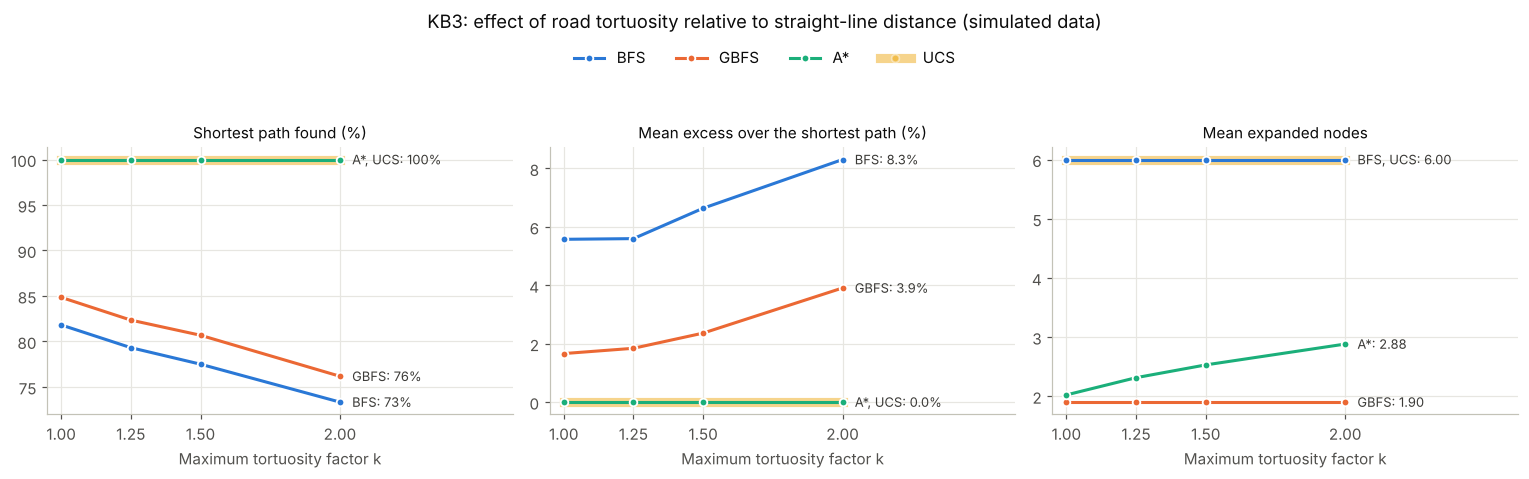

In [21]:
# Figure: sensitivity to the tortuosity factor k
# Some lines coincide (e.g. A* and UCS both at 100%), so UCS is drawn thick underneath
# and each line end is labelled with every algorithm at that value.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
chi_so = [("Tỷ lệ tối ưu (%)", "Shortest path found (%)", "{:.0f}%"),
          ("Vượt tối ưu TB (%)", "Mean excess over the shortest path (%)", "{:.1f}%"),
          ("Node mở rộng TB", "Mean expanded nodes", "{:.2f}")]
kieu_ve = {"UCS": dict(lw=6, alpha=0.45, zorder=2), "BFS": dict(lw=2, zorder=3),
           "GBFS": dict(lw=2, zorder=4), "A*": dict(lw=2, zorder=5)}
for ax, (cot_df, tieu_de, dinh_dang) in zip(axes, chi_so):
    bang = tong_hop_kb3.pivot(index="k", columns="Thuật toán", values=cot_df)[THU_TU_TT]
    for ten_tt in ["UCS", "BFS", "GBFS", "A*"]:
        ax.plot(bang.index, bang[ten_tt], color=MAU[ten_tt], marker="o", ms=5, mec="white", mew=1.2,
                label=ten_tt, **kieu_ve[ten_tt])
    # end-of-line labels, merging algorithms with the same value
    cuoi = bang.iloc[-1]
    nhom = {}
    for ten_tt in THU_TU_TT:
        nhom.setdefault(round(cuoi[ten_tt], 6), []).append(ten_tt)
    for gia_tri, ten in nhom.items():
        ax.annotate(f"{', '.join(ten)}: {dinh_dang.format(gia_tri)}", (bang.index[-1], gia_tri), xytext=(8, 0),
                    textcoords="offset points", va="center", fontsize=8.5, color="#3b3a37")
    ax.set_title(tieu_de, fontsize=10)
    ax.set_xlabel("Maximum tortuosity factor k")
    ax.set_xticks(KB3_HE_SO_TOI_DA)
    ax.set_xlim(KB3_HE_SO_TOI_DA[0] - 0.05, KB3_HE_SO_TOI_DA[-1] + 0.62)
duong_ve, nhan = axes[0].get_legend_handles_labels()
thu_tu_nhan = [nhan.index(t) for t in THU_TU_TT]
fig.legend([duong_ve[i] for i in thu_tu_nhan], THU_TU_TT, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 0.93))
fig.suptitle("KB3: effect of road tortuosity relative to straight-line distance (simulated data)", fontsize=12)
plt.tight_layout(rect=(0, 0, 1, 0.86))
plt.savefig(os.path.join(THU_MUC_THI_NGHIEM, "hinh4_kb3_do_nhay.png"), dpi=150, bbox_inches="tight")
plt.show()

### 5.2.4 KB4: tăng quy mô bản đồ (mô phỏng)

Bản đồ 12 quận quá nhỏ để thấy khác biệt khi bản đồ lớn lên. KB4 tạo đồ thị ngẫu nhiên kiểu mạng đường: điểm rải ngẫu nhiên với mật độ không đổi (khoảng 9 km² mỗi node), cạnh là lưới tam giác Delaunay, độ dài cạnh = đường chim bay × hệ số ngẫu nhiên trong [1; 1,25]. Mỗi kích thước 25, 50, 100, 200, 400, 800 node có 10 đồ thị × 30 cặp kho–đích. Đồ thị lớn không vét cạn được, nên đáp án chuẩn là UCS. Số liệu KB4 là **mô phỏng**.

In [22]:
KB4_KICH_THUOC = [25, 50, 100, 200, 400, 800]
KB4_SO_DO_THI, KB4_SO_CAP, KB4_HE_SO_QUANH_CO, KB4_SEED = 10, 30, 1.25, 2026
from shapely.geometry import MultiPoint


def tao_do_thi_ngau_nhien(n, rng):
    canh_ban_do = 3.0 * math.sqrt(n)                     # mật độ không đổi: ~9 km² mỗi node
    td = {f"N{i:03d}": (rng.uniform(0, canh_ban_do), rng.uniform(0, canh_ban_do)) for i in range(n)}
    ten_theo_diem = {v: k for k, v in td.items()}
    cp = {}
    for ln in shapely.delaunay_triangles(MultiPoint(list(td.values())), only_edges=True).geoms:
        (x1, y1), (x2, y2) = ln.coords
        a, b = ten_theo_diem[(x1, y1)], ten_theo_diem[(x2, y2)]
        cp[khoa(a, b)] = math.dist((x1, y1), (x2, y2)) * rng.uniform(1.0, KB4_HE_SO_QUANH_CO)
    return DoThi(td, {k: k for k in td}, cp)


hang_kb4 = []
t_bat_dau = time.perf_counter()
for n in KB4_KICH_THUOC:
    for lan in range(KB4_SO_DO_THI):
        rng = random.Random(f"{KB4_SEED}-{n}-{lan}")
        G4 = tao_do_thi_ngau_nhien(n, rng)
        assert not kiem_tra_heuristic(G4)
        nodes = list(G4.toa_do)
        for _ in range(KB4_SO_CAP):
            depot, goal = rng.sample(nodes, 2)
            kq = {ten: ham(G4, depot, goal) for ten, ham in THUAT_TOAN.items()}
            toi_uu = tong_km(G4, kq["UCS"]["duong"])
            it_canh = len(kq["BFS"]["duong"]) - 1
            for ten, r in kq.items():
                d = r["duong"]; km = tong_km(G4, d)
                # Kiểm chứng: đường hợp lệ; A* bằng UCS; BFS ít cạnh nhất; GBFS khớp cài đặt độc lập (đồ thị ≤ 200 node)
                assert duong_hop_le(G4, d, depot, goal)
                if ten in ("A*", "UCS"): assert abs(km - toi_uu) < EPS
                if ten != "BFS": assert len(d) - 1 >= it_canh
                if ten == "GBFS" and n <= 200:
                    d2, m2 = gbfs_doc_lap(G4, depot, goal); assert d2 == d and m2 == r["mo_rong"]
                hang_kb4.append({"Số node": n, "Thuật toán": ten, "Node mở rộng": len(r["mo_rong"]),
                                 "Tối ưu": abs(km - toi_uu) < EPS, "Vượt tối ưu (%)": 100 * (km / toi_uu - 1),
                                 "Frontier lớn nhất": r["frontier_max"]})
df_kb4 = pd.DataFrame(hang_kb4)
print(f"KB4: {len(df_kb4):,} lần chạy trong {time.perf_counter() - t_bat_dau:.1f} giây, tất cả qua kiểm chứng.")
df_kb4.to_csv(os.path.join(THU_MUC_THI_NGHIEM, "kb4_ket_qua.csv"), index=False, encoding="utf-8-sig")

tong_hop_kb4 = (df_kb4.groupby(["Số node", "Thuật toán"], sort=False)
                .agg(**{"Node mở rộng TB": ("Node mở rộng", "mean"),
                        "Tỷ lệ tối ưu (%)": ("Tối ưu", lambda s: 100 * s.mean()),
                        "Vượt tối ưu TB (%)": ("Vượt tối ưu (%)", "mean"),
                        "Frontier lớn nhất TB": ("Frontier lớn nhất", "mean")}).reset_index())
tong_hop_kb4.to_csv(os.path.join(THU_MUC_THI_NGHIEM, "kb4_tong_hop.csv"), index=False, encoding="utf-8-sig")
for cot_df in ["Node mở rộng TB", "Tỷ lệ tối ưu (%)", "Vượt tối ưu TB (%)"]:
    print(cot_df + ":")
    display(tong_hop_kb4.pivot(index="Số node", columns="Thuật toán", values=cot_df)[THU_TU_TT].round(2))
p4 = tong_hop_kb4.pivot(index="Số node", columns="Thuật toán", values="Node mở rộng TB")
print("Node của A* so với UCS (%):", (100 * p4["A*"] / p4["UCS"]).round(1).to_dict())


KB4: 7,200 lần chạy trong 37.5 giây, tất cả qua kiểm chứng.
Node mở rộng TB:


Thuật toán,BFS,GBFS,A*,UCS
Số node,,,,
25,12.69,2.59,4.10,12.69
50,23.30,3.39,6.41,23.65
100,50.75,4.85,13.10,49.24
200,101.20,6.87,24.47,103.34
400,196.50,9.51,45.20,199.28
800,408.01,13.36,86.57,412.47


Tỷ lệ tối ưu (%):


Thuật toán,BFS,GBFS,A*,UCS
Số node,,,,
25,48.33,57.33,100.0,100.0
50,40.00,51.67,100.0,100.0
100,26.00,33.33,100.0,100.0
200,14.33,18.00,100.0,100.0
400,8.00,10.33,100.0,100.0
800,5.00,5.00,100.0,100.0


Vượt tối ưu TB (%):


Thuật toán,BFS,GBFS,A*,UCS
Số node,,,,
25,18.50,6.55,0.0,0.0
50,19.96,6.68,0.0,0.0
100,28.86,10.24,0.0,0.0
200,32.76,10.62,0.0,0.0
400,36.77,10.95,0.0,0.0
800,49.81,10.75,0.0,0.0


Node của A* so với UCS (%): {25: 32.3, 50: 27.1, 100: 26.6, 200: 23.7, 400: 22.7, 800: 21.0}


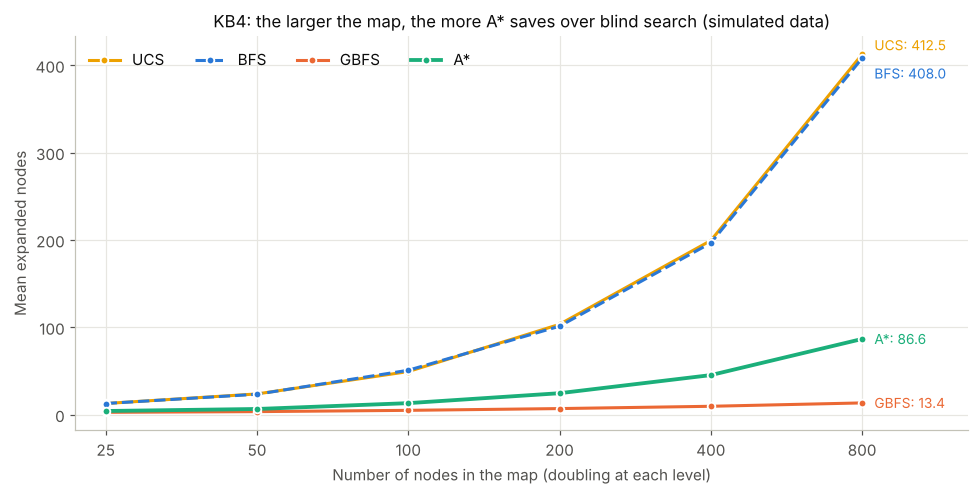

In [23]:
# Figure: expanded nodes by map size
fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(KB4_KICH_THUOC))
for ten_tt in ["UCS", "BFS", "GBFS", "A*"]:
    y = p4[ten_tt].reindex(KB4_KICH_THUOC)
    ax.plot(x, y, color=MAU[ten_tt], marker="o", ms=5, mec="white", mew=1.2, lw=2.5 if ten_tt == "A*" else 2,
            ls="--" if ten_tt == "BFS" else "-", label=ten_tt)
    ax.annotate(f"{ten_tt}: {y.iloc[-1]:.1f}", (x[-1], y.iloc[-1]), xytext=(8, 6 if ten_tt == "UCS" else (-10 if ten_tt == "BFS" else 0)),
                textcoords="offset points", va="center", fontsize=9, color=MAU[ten_tt])
ax.set_xticks(x, KB4_KICH_THUOC)
ax.set_xlim(-0.2, len(x) - 0.3)
ax.set_xlabel("Number of nodes in the map (doubling at each level)")
ax.set_ylabel("Mean expanded nodes")
ax.legend(ncol=4, loc="upper left")
ax.set_title("KB4: the larger the map, the more A* saves over blind search (simulated data)")
plt.tight_layout()
plt.savefig(os.path.join(THU_MUC_THI_NGHIEM, "hinh5_kb4_tang_quy_mo.png"), dpi=150, bbox_inches="tight")
plt.show()


## 5.3 Analysis

Ô dưới tự rút ra các nhận xét từ số liệu vừa chạy, nên các con số luôn khớp với dữ liệu hiện tại (kể cả khi nhóm điền độ dài đường thật rồi chạy lại). Phần giải thích cơ chế nằm ở ô văn bản ngay sau.

In [24]:
def pct(a, b):
    return f"{a}/{b} ({100 * a / b:.0f}%)"


print("KẾT QUẢ 1. KB1 (kho ở Ba Đình)")
for goal in KB1_KHACH_HANG:
    con = df_kb1[df_kb1["Đích"] == goal].set_index("Thuật toán")
    ngan_nhat = con["Ngắn nhất (km)"].iloc[0]
    sai = [f"{t} dài hơn {con.loc[t, 'Vượt tối ưu (%)']:.1f}%" for t in ["BFS", "GBFS"] if not con.loc[t, "Tối ưu"]]
    print(f"  - {goal}: ngắn nhất {ngan_nhat:.2f} km. "
          + ("; ".join(sai) if sai else "Cả BFS và GBFS đều tìm đúng đường ngắn nhất")
          + f". Node mở rộng BFS/GBFS/A*/UCS = "
          + "/".join(str(con.loc[t, "Node mở rộng"]) for t in THU_TU_TT) + ".")

n2 = len(cac_cap_kb2)
dem = df_kb2.groupby("Thuật toán")["Tối ưu"].sum()
print(f"\nKẾT QUẢ 2. KB2 ({n2} cặp kho–đích)")
print(f"  - A* tìm đúng đường ngắn nhất {pct(int(dem['A*']), n2)}; UCS {pct(int(dem['UCS']), n2)}.")
for t in ["BFS", "GBFS"]:
    sai = df_kb2[(df_kb2["Thuật toán"] == t) & ~df_kb2["Tối ưu"]]
    if len(sai):
        te = sai.loc[sai["Vượt tối ưu (%)"].idxmax()]
        print(f"  - {t} tìm đúng {pct(int(dem[t]), n2)}. Khi sai, đường dài hơn trung bình "
              f"{sai['Vượt tối ưu (%)'].mean():.1f}%; tệ nhất {te['Vượt tối ưu (%)']:.1f}% ({te['Kho']} → {te['Đích']}: {te['Đường đi']}).")
    else:
        print(f"  - {t} tìm đúng {pct(int(dem[t]), n2)}.")
tb = tong_hop_kb2["Node mở rộng TB"]
nhom_tb = {}
for t in tb.sort_values(kind="stable").index:
    nhom_tb.setdefault(round(tb[t], 9), []).append(t)
thu_tu = " < ".join(" = ".join(ds) for ds in nhom_tb.values())
print(f"  - Node mở rộng trung bình: " + ", ".join(f"{t} {tb[t]:.2f}" for t in THU_TU_TT) + f" (thứ tự: {thu_tu}).")
print(f"  - A* mở rộng ít hơn UCS {100 * (1 - tb['A*'] / tb['UCS']):.0f}% node, trong khi vẫn tối ưu như UCS.")
n_kho = len(node_theo_kho)
bfs_ucs_6 = int((np.isclose(node_theo_kho["BFS"], node_theo_kho["UCS"])).sum())
gbfs_le_a = int((node_theo_kho["GBFS"] <= node_theo_kho["A*"] + EPS).sum())
gbfs_eq_a = int(np.isclose(node_theo_kho["GBFS"], node_theo_kho["A*"]).sum())
a_le_ucs = int((node_theo_kho["A*"] <= node_theo_kho["UCS"] + EPS).sum())
print(f"  - Theo từng vị trí kho: BFS và UCS có cùng số node mở rộng trung bình ở {pct(bfs_ucs_6, n_kho)} vị trí "
      f"(luôn bằng {node_theo_kho['BFS'].mean():.2f}, giải thích ở mục 8 bên dưới); "
      f"GBFS mở rộng không nhiều hơn A* ở {pct(gbfs_le_a, n_kho)} vị trí (bằng nhau ở {gbfs_eq_a}); "
      f"A* mở rộng không nhiều hơn UCS ở {pct(a_le_ucs, n_kho)} vị trí.")
cap_a_hon_ucs = df_kb2.pivot_table(index=["Kho", "Đích"], columns="Thuật toán", values="Node mở rộng")
so_cap_a_nhieu_hon = int((cap_a_hon_ucs["A*"] > cap_a_hon_ucs["UCS"]).sum())
print(f"  - Xét từng cặp, A* mở rộng nhiều node hơn UCS ở {so_cap_a_nhieu_hon}/{n2} cặp.")
tg = tong_hop_kb2["Thời gian TB (µs)"]
print(f"  - Thời gian trung bình (µs): " + ", ".join(f"{t} {tg[t]:.1f}" for t in THU_TU_TT)
      + ". Chênh lệch nhỏ và phụ thuộc máy, không dùng làm căn cứ chính.")

print("\nKẾT QUẢ 3. KB3 (độ quanh co mô phỏng)")
p = {c: tong_hop_kb3.pivot(index="k", columns="Thuật toán", values=c) for c in
     ["Tỷ lệ tối ưu (%)", "Vượt tối ưu TB (%)", "Node mở rộng TB"]}
k0, k1 = KB3_HE_SO_TOI_DA[0], KB3_HE_SO_TOI_DA[-1]
for t in THU_TU_TT:
    print(f"  - {t}: tỷ lệ tối ưu {p['Tỷ lệ tối ưu (%)'].loc[k0, t]:.0f}% (k = {k0}) → {p['Tỷ lệ tối ưu (%)'].loc[k1, t]:.0f}% (k = {k1}); "
          f"node mở rộng TB {p['Node mở rộng TB'].loc[k0, t]:.2f} → {p['Node mở rộng TB'].loc[k1, t]:.2f}.")

KẾT QUẢ 1. KB1 (kho ở Ba Đình)
  - Hoàng Mai: ngắn nhất 11.25 km. BFS dài hơn 75.3%; GBFS dài hơn 25.3%. Node mở rộng BFS/GBFS/A*/UCS = 10/3/4/8.
  - Hà Đông: ngắn nhất 15.40 km. BFS dài hơn 24.0%; GBFS dài hơn 39.6%. Node mở rộng BFS/GBFS/A*/UCS = 11/3/4/11.
  - Bắc Từ Liêm: ngắn nhất 13.30 km. GBFS dài hơn 0.8%. Node mở rộng BFS/GBFS/A*/UCS = 7/2/4/9.
  - Nam Từ Liêm: ngắn nhất 14.90 km. Cả BFS và GBFS đều tìm đúng đường ngắn nhất. Node mở rộng BFS/GBFS/A*/UCS = 9/2/6/10.

KẾT QUẢ 2. KB2 (132 cặp kho–đích)
  - A* tìm đúng đường ngắn nhất 132/132 (100%); UCS 132/132 (100%).
  - BFS tìm đúng 112/132 (85%). Khi sai, đường dài hơn trung bình 35.4%; tệ nhất 101.9% (Hoàn Kiếm → Hoàng Mai: Hoàn Kiếm → Long Biên → Hoàng Mai).
  - GBFS tìm đúng 108/132 (82%). Khi sai, đường dài hơn trung bình 17.2%; tệ nhất 55.5% (Hoàng Mai → Ba Đình: Hoàng Mai → Thanh Xuân → Đống Đa → Ba Đình).
  - Node mở rộng trung bình: BFS 6.00, GBFS 1.90, A* 2.87, UCS 6.00 (thứ tự: GBFS < A* < BFS = UCS).
  - A* mở rộng

**Diễn giải cơ chế** (đọc cùng các nhận xét in ở ô trên):

1. **A\* luôn tìm đúng đường ngắn nhất.** Heuristic Euclidean nhất quán (đã kiểm tra ở mục 2.3), nên theo lý thuyết A\* dạng graph search luôn tối ưu. Số liệu ở cả ba kịch bản khớp với lý thuyết, và mọi lần chạy đều được đối chiếu với đáp án vét cạn.
2. **BFS chỉ tối ưu về số chặng, không phải số km.** BFS bỏ qua độ dài cạnh, nên luôn ra đường ít cạnh nhất (kiểm chứng đạt ở mọi lần chạy). Đường ít chặng thường đi qua những cạnh dài (trong dữ liệu hiện tại, điển hình là các cạnh qua sông Hồng nối với Long Biên), nên BFS hay dài hơn đường ngắn nhất. BFS cũng thuộc nhóm mở rộng nhiều node nhất, vì nó lan đều theo từng lớp và không có thông tin về hướng của đích (xem mục 8).
3. **GBFS thường mở rộng ít node nhất nhưng không đảm bảo tối ưu.** GBFS chỉ nhìn h(n), tức là chỉ hỏi "quận nào trông gần đích nhất", nên đi gần như thẳng đến đích và mở rộng ít node. Cái giá là đôi khi chọn một quận trông gần nhưng đường thực đi tiếp lại dài hơn.
4. **Heuristic giúp A\* tiết kiệm so với UCS.** UCS là A\* với h = 0: nó lan đều theo mọi hướng, còn A\* được h "kéo" về phía đích nên bỏ qua được nhiều node. Về lý thuyết, với h nhất quán, A\* không mở rộng node nào có f(n) > C\*, trong khi UCS phải mở rộng mọi node có g(n) < C\*. Ở mức từng cặp, A\* vẫn có thể mở rộng nhiều hơn UCS một chút do cách phá hòa điểm ở biên C\*; số cặp như vậy được in ở ô trên.
5. **Kết luận không phụ thuộc vị trí kho (KB2).** Ô trên đếm ở bao nhiêu vị trí kho thì GBFS mở rộng không nhiều hơn A\*, và A\* không nhiều hơn UCS. Nếu các quan hệ này đúng ở mọi (hoặc gần như mọi) vị trí kho, thì việc đặt kho ở đâu không làm thay đổi kết luận so sánh.
6. **Khi đường càng quanh co (KB3), heuristic càng kém chính xác.** Đường chim bay ngày càng thấp hơn quãng đường thật, nên h(n) mang ít thông tin hơn về quãng đường còn lại. BFS và GBFS không dùng độ dài cạnh khi tìm kiếm, nên đường đi và số node mở rộng của chúng không đổi theo k. Nhưng đường ngắn nhất thật thì thay đổi theo độ dài cạnh, nên đường của BFS và GBFS thường ngày càng hay lệch khỏi đường ngắn nhất. A\* vẫn luôn tối ưu; cái giá là nó được kỳ vọng phải mở rộng nhiều node hơn, tiến dần về phía UCS. Ô trên in số liệu cụ thể để đối chiếu với kỳ vọng này.
7. **Thời gian chạy** trên đồ thị 12 node chỉ vài micro giây, chênh lệch giữa các thuật toán nhỏ và dễ bị nhiễu, nên số node mở rộng là thước đo chi phí đáng tin hơn.
8. **Vì sao BFS và UCS luôn có trung bình đúng 6,00 node mở rộng.** BFS và UCS không dùng thông tin gì về đích, nên thứ tự lấy node ra khỏi frontier chỉ phụ thuộc vào kho. Nếu đích là node thứ j được lấy ra thì thuật toán đã mở rộng j − 1 node trước đó. Lấy trung bình qua cả 11 đích thì được (1 + 2 + … + 11) / 11 = 6. Vì vậy trung bình của BFS và UCS luôn bằng 6,00 với mọi vị trí kho và mọi độ dài cạnh, dù từng cặp kho–đích có thể khác nhau. Con số 6 này là mức chi phí khi tìm kiếm "mù"; khoảng cách giữa nó và số node của GBFS, A\* chính là phần tiết kiệm nhờ heuristic.

## 5.4 Bảng tổng hợp so sánh

Bảng kết hợp tính chất lý thuyết với số liệu đo được. Cột KB2 lấy từ dữ liệu bản đồ hiện tại; cột KB3 lấy ở mức đường quanh co nhất (k lớn nhất).

In [25]:
ly_thuyet = pd.DataFrame({
    "Frontier": ["Hàng đợi FIFO", "Ưu tiên theo h(n)", "Ưu tiên theo g(n) + h(n)", "Ưu tiên theo g(n)"],
    "Đầy đủ (lý thuyết)": ["Có", "Có (graph search, đồ thị hữu hạn)", "Có", "Có"],
    "Tối ưu (lý thuyết)": ["Chỉ khi mọi cạnh bằng nhau", "Không", "Có, nếu h nhất quán", "Có"],
}, index=THU_TU_TT)

k_max = KB3_HE_SO_TOI_DA[-1]
do_kb3 = tong_hop_kb3[tong_hop_kb3["k"] == k_max].set_index("Thuật toán").reindex(THU_TU_TT)
tat_ca = pd.concat([df_kb1, df_kb2, df_kb3], ignore_index=True)
kiem_chung_dat = tat_ca.groupby("Thuật toán")["Kiểm chứng"].apply(lambda s: f"{(s == 'ĐẠT').sum()}/{len(s)}")

bang_tong_hop = ly_thuyet.assign(**{
    "Tỷ lệ tối ưu KB2 (%)": tong_hop_kb2["Tỷ lệ tối ưu (%)"].round(1),
    "Vượt tối ưu TB KB2 (%)": tong_hop_kb2["Vượt tối ưu TB (%)"].round(2),
    "Node mở rộng TB KB2": tong_hop_kb2["Node mở rộng TB"].round(2),
    "Node sinh ra TB KB2": tong_hop_kb2["Node sinh ra TB"].round(2),
    "Frontier lớn nhất TB KB2": tong_hop_kb2["Frontier lớn nhất TB"].round(2),
    "Thời gian TB KB2 (µs)": tong_hop_kb2["Thời gian TB (µs)"].round(1),
    f"Tỷ lệ tối ưu KB3, k = {k_max} (%)": do_kb3["Tỷ lệ tối ưu (%)"].round(1),
    f"Node mở rộng TB KB3, k = {k_max}": do_kb3["Node mở rộng TB"].round(2),
    "Kiểm chứng đạt": kiem_chung_dat.reindex(THU_TU_TT),
})
bang_tong_hop.index.name = "Thuật toán"
display(bang_tong_hop)
bang_tong_hop.to_csv(os.path.join(THU_MUC_THI_NGHIEM, "bang_tong_hop.csv"), encoding="utf-8-sig")

so_loi = int((tat_ca["Kiểm chứng"] == "LỖI").sum())
assert so_loi == 0, f"Có {so_loi} lần chạy không qua kiểm chứng"
print(f"Tổng cộng {len(tat_ca):,} lần chạy thuật toán ở 3 kịch bản, tất cả đều qua kiểm chứng.")
if nguon_do_dai["chim bay"]:
    print(f"Lưu ý: {nguon_do_dai['chim bay']}/{len(G.chi_phi_canh)} cạnh đang tạm dùng đường chim bay; "
          "điền độ dài đường thật ở mục 2.1 rồi chạy lại để có số liệu chính thức cho KB1 và KB2.")
print(f"Các bảng (CSV) và hình (PNG) đã lưu trong: {os.path.abspath(THU_MUC_THI_NGHIEM)}")
for f in sorted(os.listdir(THU_MUC_THI_NGHIEM)):
    print("  -", f)

,Frontier,Đầy đủ (lý thuyết),Tối ưu (lý thuyết),Tỷ lệ tối ưu KB2 (%),Vượt tối ưu TB KB2 (%),Node mở rộng TB KB2,Node sinh ra TB KB2,Frontier lớn nhất TB KB2,Thời gian TB KB2 (µs),"Tỷ lệ tối ưu KB3, k = 2.0 (%)","Node mở rộng TB KB3, k = 2.0",Kiểm chứng đạt
Thuật toán,,,,,,,,,,,,
BFS,Hàng đợi FIFO,Có,Chỉ khi mọi cạnh bằng nhau,84.8,5.37,6.00,9.89,5.34,6.5,73.3,6.00,8188/8188
GBFS,Ưu tiên theo h(n),"Có (graph search, đồ thị hữu hạn)",Không,81.8,3.13,1.90,7.17,5.27,5.8,76.2,1.90,8188/8188
A*,Ưu tiên theo g(n) + h(n),Có,"Có, nếu h nhất quán",100.0,-0.00,2.87,8.30,5.48,9.2,100.0,2.88,8188/8188
UCS,Ưu tiên theo g(n),Có,Có,100.0,-0.00,6.00,10.64,5.96,12.7,100.0,6.00,8188/8188


Tổng cộng 32,752 lần chạy thuật toán ở 3 kịch bản, tất cả đều qua kiểm chứng.
Các bảng (CSV) và hình (PNG) đã lưu trong: /home/claude/hanoi_tim_duong/ket_qua/thi_nghiem
  - bang_tong_hop.csv
  - hinh1_kb1_duong_di.png
  - hinh2_kb2_node_theo_kho.png
  - hinh3_kb2_tong_hop.png
  - hinh4_kb3_do_nhay.png
  - hinh5_kb4_tang_quy_mo.png
  - kb1_ket_qua.csv
  - kb2_ket_qua.csv
  - kb3_ket_qua.csv
  - kb4_ket_qua.csv
  - kb4_tong_hop.csv


# Phần 6. Minh họa từng bước trên bản đồ mẫu

Bản đồ mẫu 11 node do nhóm tự thiết kế để có tình huống bẫy (báo cáo mục 4.1). Ô dưới chạy BFS, GBFS, A\* cho KH1 = G và in từng bước: node lấy ra, hàng xóm mới, nội dung frontier sau bước. Quy ước giống hệt Phần 2; hòa điểm theo chữ cái. Kết quả được đối chiếu với các hàm `bfs`, `gbfs`, `a_star` ở mục 2.2 (cùng đường đi, cùng số node mở rộng).

In [26]:
TOA_DO_MAU = {"S": (0, 0), "A": (5, 6), "B": (2, -2), "C": (5, -2), "D": (8, -2), "E": (4, 0), "F": (8, 1),
              "G": (10, 0), "H": (2, 4), "I": (8, 5), "J": (11, 4)}
CANH_MAU = [("S", "A", 8), ("S", "B", 3), ("S", "E", 4), ("S", "H", 5), ("A", "G", 8), ("A", "H", 4), ("A", "I", 4),
            ("B", "C", 3), ("C", "D", 3), ("D", "G", 3), ("E", "F", 5), ("F", "G", 8), ("F", "I", 4), ("I", "J", 4), ("J", "G", 5)]
G_mau = DoThi(TOA_DO_MAU, {n: n for n in TOA_DO_MAU}, {khoa(a, b): w for a, b, w in CANH_MAU})
assert not kiem_tra_heuristic(G_mau)
f2 = lambda v: f"{v:.2f}".replace(".", ",")


def trace_bfs(G, depot, goal):
    fr, parent, rows = deque([depot]), {depot: None}, []
    while fr:
        n = fr.popleft()
        if n == goal:
            rows.append((n, "ĐÍCH: dừng", "")); break
        moi = [m for m in G.neighbors[n] if m not in parent]
        for m in moi:
            parent[m] = n; fr.append(m)
        rows.append((n, ", ".join(moi) or "(không có)", ", ".join(fr)))
    return rows, build_path(parent, goal)


def trace_gbfs(G, depot, goal):
    h = lambda n: G.h(n, goal)
    fr, parent, rows = [(h(depot), G.key[depot], depot)], {depot: None}, []
    while fr:
        _, _, n = heapq.heappop(fr)
        if n == goal:
            rows.append((f"{n} (h={f2(h(n))})", "ĐÍCH: dừng", "")); break
        moi = [m for m in G.neighbors[n] if m not in parent]
        for m in moi:
            parent[m] = n; heapq.heappush(fr, (h(m), G.key[m], m))
        rows.append((f"{n} (h={f2(h(n))})", ", ".join(f"{m} (h={f2(h(m))})" for m in moi) or "(không có)",
                     " · ".join(f"{m} {f2(v)}" for v, _, m in sorted(fr))))
    return rows, build_path(parent, goal)


def trace_a_sao(G, depot, goal):
    h = lambda n: G.h(n, goal)
    g, parent, xong, rows = {depot: 0.0}, {depot: None}, set(), []
    fr = [(h(depot), G.key[depot], depot)]
    while fr:
        f, _, n = heapq.heappop(fr)
        if n in xong:
            continue                       # bản ghi cũ
        if n == goal:
            rows.append((f"{n} (g={f2(g[n])}; f={f2(f)})", "ĐÍCH: dừng", "")); break
        xong.add(n); ghi = []
        for m in G.neighbors[n]:
            if m in xong:
                continue
            gm = g[n] + G.cost(n, m)
            if m not in g or gm < g[m] - EPS:
                cu = m in g
                g[m], parent[m] = gm, n
                heapq.heappush(fr, (gm + h(m), G.key[m], m))
                ghi.append(f"{m} (g={f2(gm)}; f={f2(gm + h(m))}){' cập nhật' if cu else ''}")
        con_hieu_luc = sorted({(v, m) for v, _, m in fr if m not in xong and abs(v - (g[m] + h(m))) < EPS})
        rows.append((f"{n} (g={f2(g[n])}; f={f2(f)})", ", ".join(ghi) or "(không có)",
                     " · ".join(f"{m} {f2(v)}" for v, m in con_hieu_luc)))
    return rows, build_path(parent, goal)


DICH_MAU = "G"   # KH1; đổi thành "I" (KH2) hoặc "D" (KH3) để xem các khách khác
for ten_tt, ham_trace, ham_goc in [("BFS", trace_bfs, bfs), ("GBFS", trace_gbfs, gbfs), ("A*", trace_a_sao, a_star)]:
    rows, path = ham_trace(G_mau, "S", DICH_MAU)
    goc = ham_goc(G_mau, "S", DICH_MAU)
    so_mo_rong = sum(1 for r in rows if r[1] != "ĐÍCH: dừng")
    assert path == goc["duong"] and so_mo_rong == len(goc["mo_rong"]), f"{ten_tt}: trace không khớp mục 2.2"
    print(f"\n{ten_tt}: {' → '.join(path)} = {tong_km(G_mau, path):g} km, {so_mo_rong} node mở rộng")
    display(pd.DataFrame(rows, columns=["Lấy ra", "Hàng xóm mới / cập nhật", "Frontier sau bước"],
                         index=pd.RangeIndex(1, len(rows) + 1, name="Bước")))
u = ucs(G_mau, "S", DICH_MAU)
print(f"UCS (đối chứng): {' → '.join(u['duong'])} = {tong_km(G_mau, u['duong']):g} km, "
      f"{len(u['mo_rong'])} node mở rộng ({', '.join(u['mo_rong'])})")



BFS: S → A → G = 16 km, 5 node mở rộng


,Lấy ra,Hàng xóm mới / cập nhật,Frontier sau bước
Bước,,,
1,S,"A, B, E, H","A, B, E, H"
2,A,"G, I","B, E, H, G, I"
3,B,C,"E, H, G, I, C"
4,E,F,"H, G, I, C, F"
5,H,(không có),"G, I, C, F"
6,G,ĐÍCH: dừng,



GBFS: S → E → F → G = 17 km, 3 node mở rộng


,Lấy ra,Hàng xóm mới / cập nhật,Frontier sau bước
Bước,,,
1,"S (h=10,00)","A (h=7,81), B (h=8,25), E (h=6,00), H (h=8,94)","E 6,00 · A 7,81 · B 8,25 · H 8,94"
2,"E (h=6,00)","F (h=2,24)","F 2,24 · A 7,81 · B 8,25 · H 8,94"
3,"F (h=2,24)","G (h=0,00), I (h=5,39)","G 0,00 · I 5,39 · A 7,81 · B 8,25 · H 8,94"
4,"G (h=0,00)",ĐÍCH: dừng,



A*: S → B → C → D → G = 12 km, 6 node mở rộng


,Lấy ra,Hàng xóm mới / cập nhật,Frontier sau bước
Bước,,,
1,"S (g=0,00; f=10,00)","A (g=8,00; f=15,81), B (g=3,00; f=11,25), E (g...","E 10,00 · B 11,25 · H 13,94 · A 15,81"
2,"E (g=4,00; f=10,00)","F (g=9,00; f=11,24)","F 11,24 · B 11,25 · H 13,94 · A 15,81"
3,"F (g=9,00; f=11,24)","G (g=17,00; f=17,00), I (g=13,00; f=18,39)","B 11,25 · H 13,94 · A 15,81 · G 17,00 · I 18,39"
4,"B (g=3,00; f=11,25)","C (g=6,00; f=11,39)","C 11,39 · H 13,94 · A 15,81 · G 17,00 · I 18,39"
5,"C (g=6,00; f=11,39)","D (g=9,00; f=11,83)","D 11,83 · H 13,94 · A 15,81 · G 17,00 · I 18,39"
6,"D (g=9,00; f=11,83)","G (g=12,00; f=12,00) cập nhật","G 12,00 · H 13,94 · A 15,81 · I 18,39"
7,"G (g=12,00; f=12,00)",ĐÍCH: dừng,


UCS (đối chứng): S → B → C → D → G = 12 km, 8 node mở rộng (S, B, E, H, C, A, D, F)
